## Problem Statement

### Business Context

GlobalEdge Brokerage is a mid-sized brokerage firm operating across multiple countries, serving thousands of retail and institutional clients through a network of equity brokers. Brokers handle investment recommendations, portfolio reviews, and market advisory discussions across equity, forex, commodity, crypto, and international stock markets. Each broker manages hundreds of clients and is expected to stay updated with overnight market developments before the market opens.

Every morning, brokers must review large volumes of financial news, stock-price movements, earnings discussions, analyst commentary, and SEC regulatory filings within a very limited preparation window. In practice, brokers can only read a small portion of the available information before their first client calls begin. As a result, many important signals, disclosures, and market events remain unnoticed.

This creates an intelligence gap during client interactions. Brokers often rely on partial information, memory, or fragmented market sources while answering client questions. Important disclosures buried inside long 10-K and 10-Q filings are difficult to review manually, and brokers may struggle to provide evidence-backed responses when clients ask for justification or supporting references. This increases both compliance risk and trust-related challenges.

To solve this problem, GlobalEdge wants to build a financial intelligence assistant that allows brokers to ask natural-language questions and receive grounded answers backed by real financial data, news articles, and regulatory filings. The system should reduce information overload, improve market coverage, and help brokers make faster and more confident advisory decisions without adding technical complexity to their workflow.

### Objective

This project proposes a proof-of-concept Retrieval-Augmented Generation (RAG) financial intelligence system that combines financial news, stock-price data, and SEC filings into a searchable intelligence layer. The system uses semantic retrieval with a local Chroma vector database to fetch relevant financial context and generate grounded answers for broker questions using large language models. Brokers can ask plain-English questions such as market sentiment analysis, company-risk queries, filing-related questions, or cross-market comparisons and receive evidence-backed responses.

To improve the quality and reliability of generated answers, the system introduces a DeepEval-based prompt optimization workflow using GEPA (Genetic-Pareto Prompt Optimization). Instead of manually refining prompts, the workflow uses benchmark financial question-answer examples and evaluation metrics such as faithfulness, groundedness, relevance, and actionability to optimize the final answering prompt.

The project also evaluates multiple RAG configurations by tuning retrieval and generation parameters such as chunk size, chunk overlap, number of retrieved chunks, temperature, top-p, and maximum token limits. Each configuration is evaluated using DeepEval metrics to identify the most effective combination for grounded financial reasoning and broker-style question answering.

The final system uses the optimized prompt together with the best-performing RAG configuration to generate accurate, grounded, and production-style financial intelligence responses for broker workflows.

### Data Description

The system uses three financial intelligence datasets collected through a custom data ingestion pipeline and stored locally for the RAG workflow.
1. Global Financial News (global_news.csv)
Contains financial news articles with titles, article content, publication dates, URLs, and source metadata. The dataset covers company announcements, market developments, macroeconomic events, sector movements, and sentiment-related signals.
2. Global Stock Prices (stock_price_details.csv)
Contains historical stock-price data across global equity markets, crypto markets, and forex markets. Each record includes ticker symbols, company names, open/high/low/close prices, trading volume, and timestamps for market analysis and trend evaluation.
3. SEC Regulatory Filings (sec_filings_10k.txt)
Contains regulatory filing documents including 10-K annual reports, 10-Q quarterly reports, and other SEC disclosures. These filings include financial statements, governance information, risk disclosures, operational commentary, and compliance-related information used for grounded financial reasoning.

**What the files actually contain (verified during data preparation below):**

| File | Records | Notes |
|---|---|---|
| `global_news.csv` | 760 articles (733 after de-duplication), 137 outlets, published 17–22 Apr 2026 | `content` is truncated by the news API at ~200 characters |
| `stock_price_details.csv` | 2,986 daily OHLCV rows for 23 instruments, 23 Oct 2025 → 23 Apr 2026 | equities (US, UK, JP, HK, AU), ETFs, FX, commodities, crypto |
| `sec_filings_10k.txt` | 27 complete SEC filings (13 × 10-K, 14 × 10-Q) for Apple, Amazon, Alphabet, Microsoft, Tesla, IBM, Goldman Sachs | one filing per line, separated by `--- END OF FILING ---`, each preceded by machine-readable XBRL tags |
| `golden_benchmark_dataset.csv` | 20 broker questions with reference answers and reference context | 10 filing-based, 7 news-based, 3 price-based questions |

### Solution Approach

The notebook follows the four rubric-aligned sections of the template:

1. **Baseline RAG** – load and clean the three sources, build *source-aware* documents (contextual headers + metadata), embed them into a persistent Chroma store, define an entity-aware retriever and a grounded, citation-first prompt, and answer the five broker test cases. The pipeline is then scored with DeepEval G-Eval metrics on a held-out golden test set **and** on the five broker test cases.
2. **Prompt optimisation** – DeepEval's GEPA (Genetic-Pareto) optimiser evolves the baseline prompt against the golden training set; the optimised prompt is re-evaluated on the same held-out data.
3. **RAG tuning** – three configurations that change *both* retrieval (chunk size, chunk overlap, number of chunks) *and* generation (temperature, top-p, max tokens) are built, used to answer every test case, and evaluated.
4. **Final pipeline** – the best-scoring approach answers the five broker test cases with full source attribution, followed by business insights and recommendations.

```
 news CSV ─┐                      ┌─ SEC chunks (header: company | form | period | Item)
 price CSV ┼─► clean + enrich ────┼─ price docs (ticker-month blocks + 6-month overview)
 SEC text ─┘                      └─ news docs (title + summary, publisher, date, URL)
                                              │ text-embedding-3-small
                                              ▼
                     Chroma (cosine) ──► entity-aware retriever ──► gpt-4o-mini + grounded prompt ──► cited answer
                                                                               │
                                              DeepEval G-Eval (gpt-4o judge) ◄─┘  ──► GEPA prompt optimisation / config tuning
```

## Installing and Importing Necessary Libraries and Dependencies

In [1]:
# Installing the necessary libraries with specified versions
%pip install -qU \
    "chromadb==1.5.9" \
    "langchain-community==0.4.1" \
    "langchain-chroma==1.1.0" \
    "langchain-openai==1.2.1" \
    "langchain-text-splitters==1.1.2" \
    "pandas==3.0.3" \
    "numpy==2.4.4" \
    "scikit-learn>=1.4.0" \
    "python-dotenv>=1.0.1" \
    "tqdm>=4.66.0" \
    "deepeval==4.2.2" \
    "matplotlib>=3.8"

Note: you may need to restart the kernel to use updated packages.


**Note**:
- After running the above cell, kindly restart the runtime (for Google Colab) or notebook kernel (for VSCode), and run all cells sequentially from the next cell.
- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in ***this notebook***.

In [2]:
# Silence import-time progress-bar warnings (cosmetic only).
import warnings
warnings.filterwarnings("ignore")

# Importing the necessary libraries

# Standard Python libraries for file handling, text processing, JSON handling,
# randomness, timing, and basic utilities.
import os
import re
import json
import random
import time
from pathlib import Path
from collections import Counter
import pandas as pd

# DeepEval libraries for prompt optimization and evaluation.
from deepeval.prompt import Prompt
from deepeval.dataset import Golden
from deepeval.metrics import GEval
from deepeval.optimizer import PromptOptimizer
from deepeval.optimizer.algorithms import GEPA
from deepeval.test_case import LLMTestCase, SingleTurnParams
from deepeval.models import OpenAIModel
from deepeval.optimizer.policies import TieBreaker
from deepeval.metrics import utils as deepeval_metric_utils
from deepeval.optimizer.configs import AsyncConfig

# LangChain libraries for document loading, text splitting, embeddings,
# vector storage, and LLM interaction.
from langchain_community.document_loaders import CSVLoader, TextLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_chroma import Chroma
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_core.messages import SystemMessage, HumanMessage

# Additional libraries used in this solution:
# - html: decodes HTML entities (&#160;, &#8217; ...) present in the SEC filings
# - httpx: HTTP layer used by the OpenAI SDK (see the gateway-resilience note below)
# - numpy / matplotlib: summary statistics and charts
# - Document: LangChain's container for text + metadata
# - display / Markdown: render answers and tables cleanly in the notebook
import html
import warnings
import httpx
import numpy as np
import matplotlib.pyplot as plt
from langchain_core.documents import Document
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

## Environment Setup and Project Initialization

**Running on Google Colab (optional).** The next cell detects the runtime automatically: locally it does nothing; on Colab it mounts Google Drive, moves into the project folder and extracts the datasets zip if needed. Put `config.json` and `AI&DS_Project_3_Datasets.zip` (or the extracted folder) in one Drive folder and set `COLAB_PROJECT_DIR` to it. On Colab, run the `%pip` cell first, restart the runtime, then run all cells from the imports onwards.

In [3]:
# ── Google Colab support (no-op when running locally) ─────────────────────────
import sys
import zipfile

IN_COLAB = "google.colab" in sys.modules
COLAB_PROJECT_DIR = "/content/drive/MyDrive/Week 13"   # <- change to the Drive folder holding config.json + datasets

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir(COLAB_PROJECT_DIR)

    # Alternative without Drive: comment the three lines above and upload the files to the session.
    # from google.colab import files
    # files.upload()   # select config.json and AI&DS_Project_3_Datasets.zip

    if not Path("AI&DS_Project_3_Datasets").exists() and Path("AI&DS_Project_3_Datasets.zip").exists():
        zipfile.ZipFile("AI&DS_Project_3_Datasets.zip").extractall(".")   # zip contains AI&DS_Project_3_Datasets/

print("Runtime:", "Google Colab" if IN_COLAB else "local Jupyter", "| project folder:", Path.cwd().name)

Runtime: local Jupyter | project folder: Week 13


The OpenAI credentials are provided by the program in `config.json` (an API key and the base URL of the Great Learning OpenAI gateway). They are loaded into environment variables so that every client (LangChain, DeepEval) picks them up, and the key is never printed.

In [4]:
# Load the credentials provided for the course from config.json.
CONFIG_PATH = Path("config.json")
with open(CONFIG_PATH, "r") as file:
    config = json.load(file)

OPENAI_API_KEY = config.get("OPENAI_API_KEY")
OPENAI_API_BASE = config.get("OPENAI_API_BASE")

# Expose the credentials as environment variables used by LangChain and DeepEval.
os.environ["OPENAI_API_KEY"] = OPENAI_API_KEY
os.environ["OPENAI_BASE_URL"] = OPENAI_API_BASE

# Opt out of DeepEval's anonymous usage telemetry (no data leaves the notebook except model calls).
os.environ["DEEPEVAL_TELEMETRY_OPT_OUT"] = "YES"

print("API base URL :", OPENAI_API_BASE)
print("API key      :", OPENAI_API_KEY[:5] + "..." + f"({len(OPENAI_API_KEY)} chars, masked)")

API base URL : https://aibe.mygreatlearning.com/openai/v1
API key      : (67 chars, masked)


**Gateway resilience.** While testing, two gateway behaviours broke long runs:

1. roughly 1 – 2 % of calls returned a spurious `401 – You didn't provide an API key` even though the same request succeeded when re-sent. The OpenAI SDK and DeepEval treat a 401 as *permanent* and do not retry it, which would crash long runs such as GEPA;
2. occasionally a connection stalled without ever answering; the SDK's default 10-minute read timeout (times its own retries) froze one GEPA run for almost an hour.

The cell below therefore wraps the HTTP layer **for the gateway host only**: it re-sends a request that receives a transient 401, and caps the wait for a response at 240 seconds so a stalled connection fails fast and is retried by the SDK / DeepEval retry logic. Every other host and status code is untouched.

In [5]:
GATEWAY_HOST = httpx.URL(OPENAI_API_BASE).host
GATEWAY_RETRY_STATS = Counter()

_original_handle_request = httpx.HTTPTransport.handle_request


GATEWAY_TIMEOUT = {"connect": 15.0, "read": 240.0, "write": 60.0, "pool": 60.0}   # seconds


def _handle_request_with_gateway_retry(self, request):
    """Cap gateway response time and re-send up to 4 times when the gateway returns a transient 401."""
    if request.url.host == GATEWAY_HOST:
        request.extensions["timeout"] = GATEWAY_TIMEOUT      # a stalled call raises a retryable timeout
    for attempt in range(5):
        response = _original_handle_request(self, request)
        if response.status_code != 401 or request.url.host != GATEWAY_HOST:
            return response
        GATEWAY_RETRY_STATS["transient_401"] += 1
        response.read()
        response.close()
        time.sleep(1.0 * (attempt + 1))   # linear back-off: 1s, 2s, 3s, 4s
    return response


httpx.HTTPTransport.handle_request = _handle_request_with_gateway_retry
print(f"Transient-401 retry and {GATEWAY_TIMEOUT['read']:.0f}s response cap enabled for host: {GATEWAY_HOST}")

Transient-401 retry and 240s response cap enabled for host: aibe.mygreatlearning.com


**Model choices** (only models enabled on the course gateway were considered; `gpt-4.1`, `gpt-5*` and `text-embedding-3-large` are blocked):

| Role | Model | Why |
|---|---|---|
| Embeddings | `text-embedding-3-small` (1,536-d) | Strong retrieval quality on financial/English text (clearly ahead of `text-embedding-ada-002` on MTEB retrieval), ~5× cheaper than the large model, and fast enough to embed ~8.5k chunks in under a minute — important because Section 3 rebuilds the index once per chunking configuration. |
| Answer generation | `gpt-4o-mini` | 128k context window (multi-source contexts reach ~25 retrieved documents), low latency for a pre-call workflow, very low cost per query at broker scale (400 brokers × dozens of queries/day), and good instruction-following for citation rules. |
| Evaluation judge | `gpt-4o` | A **stronger and different** model than the generator: it reduces self-preference bias (a model grading its own outputs) and handles long, number-heavy financial contexts more reliably when judging faithfulness. |

In [6]:
# Embedding model: converts news, price blocks and SEC chunks into vectors.
EMBEDDING_MODEL = "text-embedding-3-small"

# Answer model: baseline RAG, GEPA answer generation and mutation, tuned RAG and final inference.
ANSWER_MODEL = "gpt-4o-mini"

# Evaluation model: the G-Eval judge used for every DeepEval metric.
EVAL_MODEL = "gpt-4o"

# Project paths.
DATA_DIR = Path("AI&DS_Project_3_Datasets")
NEWS_CSV = DATA_DIR / "global_news.csv"
PRICES_CSV = DATA_DIR / "stock_price_details.csv"
SEC_TXT = DATA_DIR / "sec_filings_10k.txt"
BENCHMARK_CSV = DATA_DIR / "golden_benchmark_dataset.csv"

CHROMA_DIR = Path("chroma_db")        # persistent local vector store
ARTIFACT_DIR = Path("artifacts")      # evaluation results and the selected configuration
CHROMA_DIR.mkdir(exist_ok=True)
ARTIFACT_DIR.mkdir(exist_ok=True)

# Global seed for every random operation (train/test split, GEPA).
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

for path in [NEWS_CSV, PRICES_CSV, SEC_TXT, BENCHMARK_CSV]:
    status = "OK " if path.exists() else "MISSING"
    print(f"[{status}] {path}  ({path.stat().st_size / 1e6:.2f} MB)")

[OK ] AI&DS_Project_3_Datasets/global_news.csv  (0.52 MB)
[OK ] AI&DS_Project_3_Datasets/stock_price_details.csv  (0.32 MB)
[OK ] AI&DS_Project_3_Datasets/sec_filings_10k.txt  (8.03 MB)
[OK ] AI&DS_Project_3_Datasets/golden_benchmark_dataset.csv  (0.08 MB)


In [7]:
# Shared chart style (thin bars, recessive grid, colour-blind-validated categorical palette).
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#b8b7b2",
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
    "axes.titlesize": 11,
    "font.size": 9,
})


def show_markdown(text: str) -> None:
    """Render model output as Markdown; '$' is escaped so prices are not parsed as LaTeX."""
    display(Markdown(text.replace("$", r"\$")))

# Section 1: Baseline Retrieval-Augmented Generation (RAG) Pipeline

## 1.1 Load the CSV files with `CSVLoader`

Both CSV files are loaded with LangChain's `CSVLoader`, which turns each row into a `Document`.

* **News:** the text fields (`title`, `description`, `content`) become the document body and the citation fields (`title`, `source`, `url`, `published_at`, `query`) become metadata, so every retrieved article can be cited with its headline, outlet, date and link.
* **Prices:** loaded row-by-row first to inspect the raw representation; the row documents are then re-shaped into retrieval-friendly documents (explained below).

In [8]:
# ── Financial news ────────────────────────────────────────────────────────────
news_loader = CSVLoader(
    file_path=str(NEWS_CSV),
    content_columns=["title", "description", "content"],                  # embedded text
    metadata_columns=["title", "source", "url", "published_at", "query"],  # citation fields
    encoding="utf-8",
)
news_raw_docs = news_loader.load()

# ── Daily price data ──────────────────────────────────────────────────────────
price_loader = CSVLoader(file_path=str(PRICES_CSV), encoding="utf-8")
price_row_docs = price_loader.load()

print(f"News documents loaded : {len(news_raw_docs)}")
print(f"Price row documents   : {len(price_row_docs)}")
print("\n--- Example news document ---")
print(news_raw_docs[0].page_content[:400])
print("Metadata:", {k: v for k, v in news_raw_docs[0].metadata.items() if k != "url"})
print("\n--- Example price row document ---")
print(price_row_docs[0].page_content)

News documents loaded : 760
Price row documents   : 2986

--- Example news document ---
title: What Makes Tesla (TSLA) a Long-Term Holding?
description: Investment management company Nightview Capital recently released its Q1 2026 investor letter. A copy of the letter can be downloaded here. In the first...
content: Investment management company Nightview Capital recently released its Q1 2026 investor letter. A copy of the letter can be downloaded here. In the first quarter of 2026, 
Metadata: {'source': 'Yahoo Entertainment', 'row': 0, 'title': 'What Makes Tesla (TSLA) a Long-Term Holding?', 'published_at': '2026-04-22T12:28:08Z', 'query': 'stock market'}

--- Example price row document ---
Date: 2025-10-23
ticker: 0700.HK
name: Tencent (Hong Kong)
Open: 620.0
High: 636.0
Low: 618.0
Close: 633.0
Volume: 12419348.0


In [9]:
# Quick profile of both tables to decide how to turn them into retrievable documents.
news_df = pd.read_csv(NEWS_CSV)
prices_df = pd.read_csv(PRICES_CSV, parse_dates=["Date"])

news_profile = pd.Series({
    "articles": len(news_df),
    "duplicate titles": int(news_df["title"].str.strip().str.lower().duplicated().sum()),
    "news outlets": news_df["source"].nunique(),
    "first published (UTC)": news_df["published_at"].min(),
    "last published (UTC)": news_df["published_at"].max(),
    "median content length (chars)": int(news_df["content"].str.len().median()),
    "missing descriptions": int(news_df["description"].isna().sum()),
}, name="News")
display(news_profile.to_frame())

price_profile = (
    prices_df.groupby(["ticker", "name"])
    .agg(trading_days=("Date", "count"), first_date=("Date", "min"), last_date=("Date", "max"),
         first_close=("Close", "first"), last_close=("Close", "last"))
    .assign(change_pct=lambda d: (d.last_close / d.first_close - 1) * 100)
    .round(2)
    .reset_index()
)
display(price_profile)

,News
articles,760
duplicate titles,27
news outlets,137
first published (UTC),2026-04-17T00:00:00Z
last published (UTC),2026-04-22T12:28:08Z
median content length (chars),214
missing descriptions,10


,ticker,name,trading_days,first_date,last_date,first_close,last_close,change_pct
0,0700.HK,Tencent (Hong Kong),121,2025-10-23,2026-04-23,633.00,495.20,-21.77
1,7203.T,Toyota (Tokyo),122,2025-10-23,2026-04-23,3045.65,3123.00,2.54
2,9984.T,SoftBank (Tokyo),122,2025-10-23,2026-04-23,5640.88,5837.00,3.48
3,AAPL,Apple (NASDAQ),124,2025-10-23,2026-04-22,259.09,273.17,5.44
4,AMZN,Amazon (NASDAQ),124,2025-10-23,2026-04-22,221.09,255.36,15.50
5,AZN.L,AstraZeneca (London),126,2025-10-23,2026-04-23,12494.72,14454.00,15.68
6,BHP.AX,BHP Group (ASX),125,2025-10-23,2026-04-23,42.21,56.03,32.75
7,BTC-USD,Bitcoin,183,2025-10-23,2026-04-23,110069.73,77814.03,-29.30
8,CL=F,Crude Oil Futures,125,2025-10-23,2026-04-23,61.79,92.82,50.22
9,ETH-USD,Ethereum,183,2025-10-23,2026-04-23,3856.03,2332.16,-39.52


**Design decision – re-shaping the price rows.** A single price row (`Date / ticker / name / Open / High / Low / Close / Volume`) is a poor retrieval unit:

* the 2,986 rows are almost identical in wording, so their embeddings crowd together and a question about *Tencent* easily retrieves *SPY* or *AstraZeneca* rows — exactly what happened in the reference contexts of golden questions 12–14;
* broker questions are about **periods** ("over the last few months", "late October", "during April"), which no single row can answer.

The rows are therefore regrouped into two document types per instrument, **without losing any data** (every daily OHLCV row is still present verbatim):

1. **Ticker-month blocks** (161 docs) – a header naming the instrument and month, the month's open → close change, monthly high/low *with dates*, average volume, followed by every trading day of that month.
2. **Six-month overview** (23 docs) – total change, last-30-day change, period high/low with dates, month-end closes and the five most recent sessions; this answers "how has the stock been doing?".

In [10]:
def fmt_price(value: float) -> str:
    """Use 4 decimals for FX-style quotes (< 10) and 2 decimals otherwise."""
    return f"{value:,.4f}" if value < 10 else f"{value:,.2f}"


def build_price_documents(prices: pd.DataFrame) -> list[Document]:
    """Turn daily OHLCV rows into ticker-month blocks plus one 6-month overview per instrument."""
    documents = []
    prices = prices.sort_values(["ticker", "Date"])

    for (ticker, name), g in prices.groupby(["ticker", "name"]):
        g = g.reset_index(drop=True)
        first, last = g.iloc[0], g.iloc[-1]
        high_row, low_row = g.loc[g["High"].idxmax()], g.loc[g["Low"].idxmin()]
        last_30d = g[g["Date"] >= last["Date"] - pd.Timedelta(days=30)]
        month_end = g.set_index("Date")["Close"].resample("ME").last()

        # 1) Overview document: trend-level facts for "how is it doing?" questions.
        overview = (
            f"[PRICE OVERVIEW | {name} ({ticker}) | {first['Date']:%Y-%m-%d} to {last['Date']:%Y-%m-%d}]\n"
            f"{name} ({ticker}) price trend summary. Close moved from {fmt_price(first['Close'])} on {first['Date']:%Y-%m-%d} "
            f"to {fmt_price(last['Close'])} on {last['Date']:%Y-%m-%d} ({(last['Close'] / first['Close'] - 1) * 100:+.1f}% over the period). "
            f"Last-30-day change: {(last['Close'] / last_30d.iloc[0]['Close'] - 1) * 100:+.1f}%. "
            f"Period high {fmt_price(high_row['High'])} on {high_row['Date']:%Y-%m-%d}; period low {fmt_price(low_row['Low'])} on {low_row['Date']:%Y-%m-%d}. "
            "Month-end closes: " + "; ".join(f"{d:%b %Y} {fmt_price(v)}" for d, v in month_end.items()) + ". "
            "Most recent sessions: " + "; ".join(f"{r.Date:%Y-%m-%d} close {fmt_price(r.Close)}" for r in g.tail(5).itertuples()) + "."
        )
        documents.append(Document(page_content=overview, metadata={
            "source_type": "price", "source_file": PRICES_CSV.name, "ticker": ticker, "company": name,
            "doc_kind": "overview", "period": f"{first['Date']:%Y-%m-%d} to {last['Date']:%Y-%m-%d}",
        }))

        # 2) One block per calendar month with every daily row kept verbatim.
        for month, m in g.groupby(g["Date"].dt.to_period("M")):
            m = m.reset_index(drop=True)
            m_high, m_low = m.loc[m["High"].idxmax()], m.loc[m["Low"].idxmin()]
            daily_rows = "\n".join(
                f"{r.Date:%Y-%m-%d}: open {fmt_price(r.Open)}, high {fmt_price(r.High)}, low {fmt_price(r.Low)}, "
                f"close {fmt_price(r.Close)}, volume {r.Volume:,.0f}"
                for r in m.itertuples()
            )
            block = (
                f"[PRICE DATA | {name} ({ticker}) | {month.strftime('%B %Y')}]\n"
                f"{name} ({ticker}) daily prices for {month.strftime('%B %Y')}: first open {fmt_price(m.iloc[0]['Open'])}, "
                f"last close {fmt_price(m.iloc[-1]['Close'])} ({(m.iloc[-1]['Close'] / m.iloc[0]['Open'] - 1) * 100:+.1f}% for the month). "
                f"Monthly high {fmt_price(m_high['High'])} on {m_high['Date']:%Y-%m-%d}; monthly low {fmt_price(m_low['Low'])} on {m_low['Date']:%Y-%m-%d}. "
                f"Average daily volume {m['Volume'].mean():,.0f}.\n{daily_rows}"
            )
            documents.append(Document(page_content=block, metadata={
                "source_type": "price", "source_file": PRICES_CSV.name, "ticker": ticker, "company": name,
                "doc_kind": "month", "period": month.strftime("%Y-%m"),
            }))
    return documents


price_docs = build_price_documents(prices_df)
print(f"Price documents: {len(price_docs)}  "
      f"({sum(d.metadata['doc_kind'] == 'month' for d in price_docs)} ticker-month blocks + "
      f"{sum(d.metadata['doc_kind'] == 'overview' for d in price_docs)} overviews)")
print("\n--- Example overview document ---")
print(price_docs[0].page_content)

Price documents: 184  (161 ticker-month blocks + 23 overviews)

--- Example overview document ---
[PRICE OVERVIEW | Tencent (Hong Kong) (0700.HK) | 2025-10-23 to 2026-04-23]
Tencent (Hong Kong) (0700.HK) price trend summary. Close moved from 633.00 on 2025-10-23 to 495.20 on 2026-04-23 (-21.8% over the period). Last-30-day change: -3.7%. Period high 664.00 on 2025-10-30; period low 476.00 on 2026-03-30. Month-end closes: Oct 2025 629.00; Nov 2025 611.50; Dec 2025 599.00; Jan 2026 606.00; Feb 2026 518.00; Mar 2026 484.00; Apr 2026 495.20. Most recent sessions: 2026-04-17 close 510.50; 2026-04-20 close 522.50; 2026-04-21 close 519.00; 2026-04-22 close 504.00; 2026-04-23 close 495.20.


**Design decision – entity tagging.** Brokers ask about named holdings ("Apple", "Bitcoin", "the yen"). Every document is tagged with the instrument it is about (`ticker` metadata), using a small alias dictionary covering the 23 priced instruments and the 7 filers. The same dictionary is later used to detect entities in the broker's question, which enables metadata-filtered retrieval. News articles that do not name a covered instrument are tagged `MARKET`.

In [11]:
# Alias dictionary: ticker -> phrases that identify it in news text and in broker questions.
ENTITY_ALIASES = {
    "AAPL": ["apple", "aapl", "tim cook"],
    "AMZN": ["amazon", "amzn", "aws"],
    "GOOGL": ["alphabet", "google", "googl", "goog"],
    "MSFT": ["microsoft", "msft"],
    "TSLA": ["tesla", "tsla"],
    "IBM": ["ibm"],
    "GS": ["goldman"],
    "JPM": ["jpmorgan", "jp morgan", "jpm"],
    "SAP": ["sap se"],
    "0700.HK": ["tencent"],
    "7203.T": ["toyota"],
    "9984.T": ["softbank"],
    "AZN.L": ["astrazeneca"],
    "BHP.AX": ["bhp"],
    "SHEL.L": ["shell plc"],
    "BTC-USD": ["bitcoin", "btc"],
    "ETH-USD": ["ethereum"],
    "CL=F": ["crude", "oil", "wti", "brent"],
    "GC=F": ["gold"],
    "SI=F": ["silver"],
    "EURUSD=X": ["eurusd", "eur/usd", "euro"],
    "GBPUSD=X": ["gbpusd", "gbp/usd", "sterling"],
    "USDJPY=X": ["usdjpy", "usd/jpy", "yen"],
    "SPY": ["s&p 500", "s&p"],
    "QQQ": ["nasdaq 100", "nasdaq-100", "qqq"],
}
# Whole-word, case-insensitive patterns ("gold" must not match "Goldman").
ALIAS_PATTERNS = {
    ticker: re.compile(r"\b(" + "|".join(re.escape(a) for a in aliases) + r")\b", re.IGNORECASE)
    for ticker, aliases in ENTITY_ALIASES.items()
}


def detect_entities(text: str) -> list[str]:
    """Return the tickers mentioned in a text, ordered by first mention."""
    hits = [(m.start(), ticker) for ticker, pattern in ALIAS_PATTERNS.items() if (m := pattern.search(text))]
    return [ticker for _, ticker in sorted(hits)]


def build_news_documents(raw_docs: list[Document]) -> list[Document]:
    """De-duplicate articles by headline and attach clean citation metadata."""
    seen_titles, documents = set(), []
    for doc in raw_docs:
        title_key = doc.metadata["title"].strip().lower()
        if title_key in seen_titles:          # syndicated duplicates add noise, not information
            continue
        seen_titles.add(title_key)
        entities = detect_entities(doc.page_content)
        documents.append(Document(page_content=doc.page_content, metadata={
            "source_type": "news",
            "source_file": NEWS_CSV.name,
            "title": doc.metadata["title"],
            "publisher": doc.metadata["source"],
            "url": doc.metadata["url"],
            "published_at": doc.metadata["published_at"],
            "query": doc.metadata["query"],
            "ticker": entities[0] if entities else "MARKET",
        }))
    return documents


news_docs = build_news_documents(news_raw_docs)
print(f"News documents after de-duplication: {len(news_docs)} (removed {len(news_raw_docs) - len(news_docs)} duplicates)")
display(pd.Series([d.metadata["ticker"] for d in news_docs]).value_counts().head(12).rename("articles").to_frame().T)

News documents after de-duplication: 733 (removed 27 duplicates)


,MARKET,BTC-USD,CL=F,SPY,GC=F,AAPL,GOOGL,ETH-USD,GS,TSLA,SI=F,JPM
articles,481,78,77,29,15,12,9,8,7,5,4,3


**Observations – loading the CSV files**

- **News:** 760 articles from 137 outlets, all published in a five-day window (17 – 22 April 2026), which matches the "this week's news" framing of the broker questions. 27 headlines were syndicated duplicates and were removed (733 unique articles); 10 articles have no description but all have a title and content.
- The news API truncates `content` to ~214 characters (median), so each article is effectively *headline + summary + first sentence*. This is enough to capture sentiment and the key fact of an article, but not the full story – answers about news are therefore necessarily high-level.
- Only 34 % of the articles name one of the covered instruments; 481 are general market pieces (tagged `MARKET`). Bitcoin (78) and oil (77) dominate the instrument-specific news, mirroring the crypto rally and the Strait of Hormuz crisis that week.
- **Prices:** 2,986 daily rows for 23 instruments over six months (23 Oct 2025 → 23 Apr 2026), with no missing values. The period was highly dispersed: silver +58 %, crude oil +50 % and Alphabet +34 %, versus Ethereum −40 %, SAP −38 %, Bitcoin −29 % and Tencent −22 %. A broker cannot hold this in memory, which is exactly why the price data must be queryable.
- The raw `CSVLoader` row document (`Open: 620.0 / High: 636.0 …`) is a weak retrieval unit: rows are near-identical in wording and a single day cannot answer period questions. Re-shaping them into **161 ticker-month blocks + 23 six-month overviews** keeps every daily value while making each document self-describing (instrument and month in the header), so it can be found by questions such as "Tencent in late October 2025" or "how has the stock been doing?".

## 1.2 Load the SEC filings text and split it into chunks

The SEC file is a single text file holding **27 complete filings**, one per line, each ending with `--- END OF FILING ---`. Each filing starts with a block of machine-readable XBRL tags (e.g. `http://fasb.org/us-gaap/2024#DerivativeAssets ...`, up to 220k characters for Goldman Sachs) that carries no meaning for a broker, and the text contains HTML entities (`&#160;`, `&#8217;`). Cleaning steps:

1. split on the end-of-filing marker;
2. identify the filer from its SEC **CIK** number (Microsoft's filings have no ticker prefix, so the CIK is the reliable key);
3. decode HTML entities and drop everything before the cover page ("UNITED STATES SECURITIES AND EXCHANGE COMMISSION");
4. extract the **form type** (10-K / 10-Q) and **period end date** from the cover page.

In [12]:
# SEC Central Index Key -> (ticker, legal name)
CIK_TO_COMPANY = {
    "0000320193": ("AAPL", "Apple Inc."),
    "0001018724": ("AMZN", "Amazon.com, Inc."),
    "0001652044": ("GOOGL", "Alphabet Inc."),
    "0000789019": ("MSFT", "Microsoft Corporation"),
    "0001318605": ("TSLA", "Tesla, Inc."),
    "0000051143": ("IBM", "International Business Machines Corp."),
    "0000886982": ("GS", "The Goldman Sachs Group, Inc."),
}

COVER_PAGE_RE = re.compile(r"UNITED STATES\s+SECURITIES AND EXCHANGE COMMISSION", re.IGNORECASE)
PERIOD_RE = re.compile(
    r"For the (?:quarterly period|fiscal year|quarter|year) ended\s*:?\s*([A-Za-z]+\s+\d{1,2}\s*,\s*\d{4})",
    re.IGNORECASE,
)


def parse_sec_filings(path: Path) -> list[dict]:
    """Split the raw file into filings and return clean text plus filing-level metadata."""
    raw_text = path.read_text(encoding="utf-8")
    filings = []
    for block in (b.strip() for b in raw_text.split("--- END OF FILING ---")):
        if not block:
            continue
        cik = re.search(r"\b(\d{10})\b", block[:500]).group(1)        # CIK appears in the XBRL header
        ticker, company = CIK_TO_COMPANY[cik]
        text = html.unescape(block).replace("\xa0", " ")
        body = re.sub(r"\s+", " ", text[COVER_PAGE_RE.search(text).start():]).strip()
        form_type = "10-K" if re.search(r"FORM\s+10\s*-\s*K", body[:600], re.IGNORECASE) else "10-Q"
        period_raw = re.sub(r"\s+,", ",", PERIOD_RE.search(body[:3000]).group(1)).title()
        filings.append({
            "ticker": ticker,
            "company": company,
            "form_type": form_type,
            "period_end": pd.to_datetime(period_raw).strftime("%Y-%m-%d"),
            "raw_chars": len(block),
            "clean_chars": len(body),
            "body": body,
        })
    return filings


sec_filings = parse_sec_filings(SEC_TXT)
filings_df = pd.DataFrame(sec_filings).drop(columns="body").sort_values(["ticker", "period_end"]).reset_index(drop=True)
print(f"Filings parsed: {len(sec_filings)} | characters kept after cleaning: "
      f"{filings_df.clean_chars.sum() / filings_df.raw_chars.sum():.0%} of the raw text")
display(filings_df)

Filings parsed: 27 | characters kept after cleaning: 74% of the raw text


,ticker,company,form_type,period_end,raw_chars,clean_chars
0,AAPL,Apple Inc.,10-K,2024-09-28,230963,204307
1,AAPL,Apple Inc.,10-Q,2025-06-28,78579,59885
2,AAPL,Apple Inc.,10-K,2025-09-27,233148,206713
3,AAPL,Apple Inc.,10-Q,2025-12-27,72361,56958
4,AMZN,"Amazon.com, Inc.",10-K,2024-12-31,322545,280152
5,AMZN,"Amazon.com, Inc.",10-Q,2025-06-30,202741,172067
6,AMZN,"Amazon.com, Inc.",10-Q,2025-09-30,212504,180855
7,AMZN,"Amazon.com, Inc.",10-K,2025-12-31,326605,283445
8,GOOGL,Alphabet Inc.,10-K,2024-12-31,396386,350746
9,GOOGL,Alphabet Inc.,10-Q,2025-06-30,205032,153094


**Text-splitting mechanism and parameters.**

* **Splitter – `RecursiveCharacterTextSplitter`** with separators `["\n\n", "\n", ". ", "; ", " ", ""]`. The filings have no line breaks (each is one long line), so the default separators would fall straight through to splitting on spaces mid-sentence. Adding `". "` and `"; "` makes the splitter cut at **sentence boundaries** first, keeping a disclosure sentence and the numbers it quotes together.
* **`chunk_size = 1000` characters (~250 tokens).** A typical risk-factor paragraph, an Item 9A controls statement or a row-group of an income statement fits in 600–1,200 characters. Smaller chunks (≤ 500) separate numbers from their labels; much larger chunks (≥ 2,000) mix several topics and dilute the embedding. 1,000 is the precise-but-complete middle ground (Section 3 tests 700, 1,200 and 1,800).
* **`chunk_overlap = 150` characters (15 %).** Enough to carry one sentence across a boundary so a statement split between chunks is still retrievable intact, without duplicating too much text in the index.
* **Contextual header on every chunk.** A chunk such as *"The Company's stock has experienced substantial price volatility..."* does not say *which* company or filing it comes from. Each chunk is prefixed with `[SEC 10-K | Apple Inc. (AAPL) | period ended 2025-09-27 | Item 1A - Risk Factors]`, so the embedding carries company, form, period and section, and the LLM can cite the exact filing. The Item (section) is derived from the last `Item X.` heading preceding the chunk.
* **News and price documents are not split.** They are already self-contained records (news ≈ 450 characters; price blocks 0.6 – 3.3k characters) and splitting would separate a price row from the header that names the instrument.

In [13]:
# Item numbers -> section names, which differ between annual (10-K) and quarterly (10-Q) reports.
ITEM_NAMES = {
    "10-K": {"1": "Business", "1A": "Risk Factors", "1B": "Unresolved Staff Comments", "1C": "Cybersecurity",
             "2": "Properties", "3": "Legal Proceedings", "5": "Market for Common Equity", "7": "MD&A",
             "7A": "Market Risk Disclosures", "8": "Financial Statements", "9A": "Controls and Procedures",
             "9B": "Other Information", "10": "Directors and Officers", "11": "Executive Compensation",
             "15": "Exhibits and Signatures"},
    "10-Q": {"1": "Financial Statements / Legal Proceedings", "1A": "Risk Factors", "2": "MD&A",
             "3": "Market Risk Disclosures", "4": "Controls and Procedures", "5": "Other Information",
             "6": "Exhibits and Signatures"},
}
ITEM_HEADING_RE = re.compile(r"\bItem\s+(1A|1B|1C|7A|9A|9B|9C|1[0-6]|[1-9])\s*\.", re.IGNORECASE)

SEC_SEPARATORS = ["\n\n", "\n", ". ", "; ", " ", ""]
DEFAULT_CHUNK_SIZE = 1000
DEFAULT_CHUNK_OVERLAP = 150


def chunk_sec_filings(filings: list[dict], chunk_size: int, chunk_overlap: int) -> list[Document]:
    """Split every filing into sentence-aware chunks and prefix each with a contextual header."""
    splitter = RecursiveCharacterTextSplitter(
        chunk_size=chunk_size,
        chunk_overlap=chunk_overlap,
        separators=SEC_SEPARATORS,
        add_start_index=True,     # character offset of the chunk -> used to find its Item heading
    )
    chunks = []
    for filing in filings:
        headings = [(m.start(), m.group(1).upper()) for m in ITEM_HEADING_RE.finditer(filing["body"])]
        for piece in splitter.split_documents([Document(page_content=filing["body"])]):
            start = piece.metadata["start_index"]
            item = next((it for pos, it in reversed(headings) if pos <= start), None)
            section = f"Item {item} - {ITEM_NAMES[filing['form_type']].get(item, 'Other')}" if item else "Cover page"
            header = (f"[SEC {filing['form_type']} | {filing['company']} ({filing['ticker']}) | "
                      f"period ended {filing['period_end']} | {section}]")
            chunks.append(Document(
                page_content=f"{header}\n{piece.page_content.lstrip('. ')}",
                metadata={
                    "source_type": "sec_filing", "source_file": SEC_TXT.name,
                    "ticker": filing["ticker"], "company": filing["company"],
                    "form_type": filing["form_type"], "period_end": filing["period_end"],
                    "section": section, "char_start": start,
                },
            ))
    return chunks


sec_chunks = chunk_sec_filings(sec_filings, DEFAULT_CHUNK_SIZE, DEFAULT_CHUNK_OVERLAP)
chunk_lengths = pd.Series([len(c.page_content) for c in sec_chunks])

print(f"SEC chunks: {len(sec_chunks):,} | median length {chunk_lengths.median():.0f} chars | "
      f"95th percentile {chunk_lengths.quantile(0.95):.0f} chars")
print("\n--- Example SEC chunk ---")
print(sec_chunks[1500].page_content[:600])
print("\nMetadata:", sec_chunks[1500].metadata)

SEC chunks: 7,590 | median length 991 chars | 95th percentile 1102 chars

--- Example SEC chunk ---
[SEC 10-K | Tesla, Inc. (TSLA) | period ended 2025-12-31 | Item 9A - Controls and Procedures]
72 Note 8 – Other Long-Term Liabilities Our other long-term liabilities consisted of the following (in millions): December 31, 2025 December 31, 2024 Accrued warranty reserve $ 6,132 $ 4,799 Operating lease liabilities 5,389 4,603 Other non-current liabilities 1,339 1,093 Total other long-term liabilities $ 12,860 $ 10,495 Note 9 – Debt The following is a summary of our debt and finance leases as of December 31, 2025 (in millions): Net Carrying Value Unpaid Principal Balance Unused Committed Amount (1

Metadata: {'source_type': 'sec_filing', 'source_file': 'sec_filings_10k.txt', 'ticker': 'TSLA', 'company': 'Tesla, Inc.', 'form_type': '10-K', 'period_end': '2025-12-31', 'section': 'Item 9A - Controls and Procedures', 'char_start': 304321}


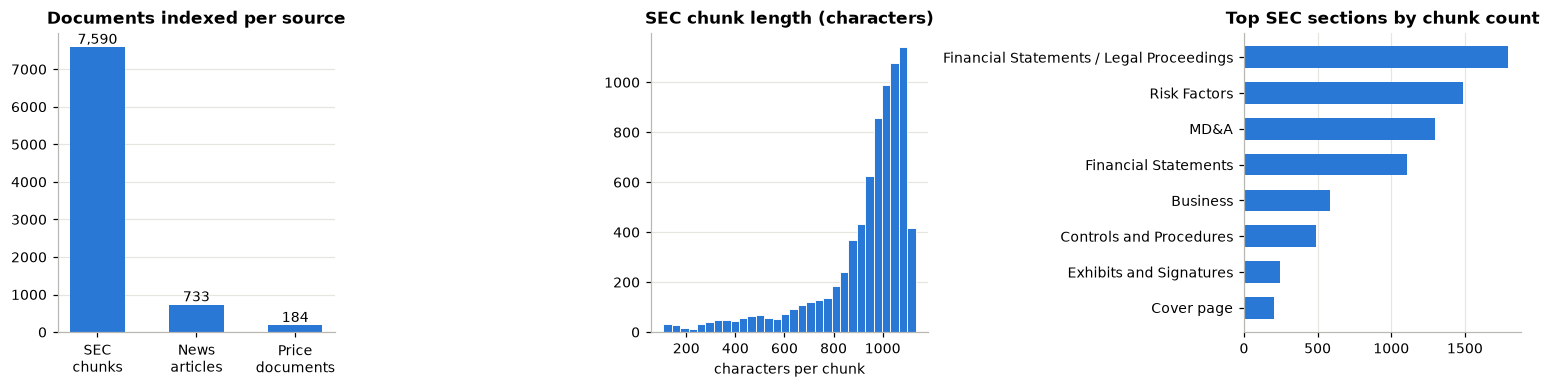

In [14]:
# Visual summary of the prepared corpus.
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))

corpus_counts = pd.Series({"SEC\nchunks": len(sec_chunks), "News\narticles": len(news_docs), "Price\ndocuments": len(price_docs)})
axes[0].bar(corpus_counts.index, corpus_counts.values, color=PALETTE[0], width=0.55)
for x, v in enumerate(corpus_counts.values):
    axes[0].text(x, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
axes[0].set_title("Documents indexed per source")

axes[1].hist(chunk_lengths, bins=30, color=PALETTE[0], edgecolor="white", linewidth=0.6)
axes[1].set_title("SEC chunk length (characters)")
axes[1].set_xlabel("characters per chunk")

section_counts = pd.Series([c.metadata["section"].split(" - ")[-1] for c in sec_chunks]).value_counts().head(8)[::-1]
axes[2].barh(section_counts.index, section_counts.values, color=PALETTE[0], height=0.6)
axes[2].grid(axis="x", color="#e6e5e0"); axes[2].grid(axis="y", visible=False)
axes[2].set_title("Top SEC sections by chunk count")

plt.tight_layout()
plt.show()

**Observations – SEC filings and chunking**

- The file contains **27 filings for 7 companies** (13 × 10-K, 14 × 10-Q) covering fiscal periods from June 2024 to March 2026, not a single 10-Q. Each company has 3 – 4 consecutive reports, so *which period* a figure comes from matters as much as the figure itself – this is why period-end dates were extracted into metadata and the chunk header.
- Cleaning removed 26 % of the raw characters (the XBRL tag block before the cover page and HTML entities). The three Goldman Sachs filings are exactly 500,000 raw characters each, which suggests the data provider capped them; their later sections may be incomplete.
- With `chunk_size = 1000` / `chunk_overlap = 150` the filings produce **7,590 chunks** with a median length of 991 characters and a 95th percentile of 1,102 (the header adds ~100 characters). The tight distribution shows the sentence-aware separators work: chunks end at sentence boundaries instead of being cut at an arbitrary character.
- Financial statements, risk factors and MD&A account for the largest share of chunks, which is where broker questions about results, risks and outlook will be answered.
- The section label is a heuristic based on the last `Item X.` heading before the chunk. It is right for most chunks, but cross-references inside the text can mislabel a chunk – the Tesla example above is a debt note labelled *Item 9A*. Company, form and period (the fields used for filtering and citation) come from the cover page and are reliable.

## 1.3 Build a local Chroma vector store

**Vector store setup.** A persistent, local **Chroma** collection (cosine distance, matching how OpenAI embeddings are normalised) holds all three sources in one index, with metadata (`source_type`, `ticker`, `form_type`, `period_end`, `section`, `title`, `url`, ...) stored alongside each vector so it can be filtered on and cited. The builder function is reused in Section 3, where each chunking configuration gets its own collection; an existing collection with the expected number of documents is reused instead of re-embedding.

In [15]:
embeddings = OpenAIEmbeddings(
    model=EMBEDDING_MODEL,
    chunk_size=500,            # texts per embedding request (keeps each request well under the token limit)
    api_key=os.getenv("OPENAI_API_KEY"),
    base_url=os.getenv("OPENAI_BASE_URL"),
)

VECTORSTORES = {}   # (chunk_size, chunk_overlap) -> Chroma collection, shared with Section 3


def build_vectorstore(chunk_size: int, chunk_overlap: int, batch_size: int = 2000) -> Chroma:
    """Create (or reuse) a Chroma collection containing SEC chunks + news + price documents."""
    key = (chunk_size, chunk_overlap)
    if key in VECTORSTORES:
        return VECTORSTORES[key]

    sec_docs = chunk_sec_filings(sec_filings, chunk_size, chunk_overlap)
    all_docs = sec_docs + news_docs + price_docs

    store = Chroma(
        collection_name=f"globaledge_cs{chunk_size}_co{chunk_overlap}",
        embedding_function=embeddings,
        persist_directory=str(CHROMA_DIR),
        collection_metadata={"hnsw:space": "cosine"},
    )
    if store._collection.count() != len(all_docs):
        # Stale or empty collection: rebuild it from scratch.
        store.reset_collection()
        start = time.time()
        for i in range(0, len(all_docs), batch_size):     # Chroma caps the number of records per insert
            store.add_documents(all_docs[i:i + batch_size])
        print(f"Embedded {len(all_docs):,} documents in {time.time() - start:.0f}s")
    else:
        print(f"Re-using persisted collection with {len(all_docs):,} documents")

    VECTORSTORES[key] = store
    return store


vectorstore = build_vectorstore(DEFAULT_CHUNK_SIZE, DEFAULT_CHUNK_OVERLAP)

stored = vectorstore.get(include=["metadatas"])["metadatas"]
display(pd.Series([m["source_type"] for m in stored]).value_counts().rename("vectors").to_frame().T)

Re-using persisted collection with 8,507 documents


,sec_filing,news,price
vectors,7590,733,184


In [16]:
# Sanity check: one plain similarity search per source type.
for probe in ["Apple internal control over financial reporting material weakness",
              "oil prices Strait of Hormuz blockade",
              "Tencent daily closing prices October 2025"]:
    top = vectorstore.similarity_search(probe, k=1)[0]
    print(f"Query: {probe}\n  -> {top.page_content[:150]}...\n")

Query: Apple internal control over financial reporting material weakness
  -> [SEC 10-K | Apple Inc. (AAPL) | period ended 2024-09-28 | Item 9A - Controls and Procedures]
Inherent Limitations over Internal Controls The Company’s...



Query: oil prices Strait of Hormuz blockade
  -> title: Strait of Hormuz Crisis Escalates as Traffic Halts Amid US-Iran Tensions on April 21
description: DUBAI, United Arab Emirates — Maritime traffi...



Query: Tencent daily closing prices October 2025
  -> [PRICE DATA | Tencent (Hong Kong) (0700.HK) | October 2025]
Tencent (Hong Kong) (0700.HK) daily prices for October 2025: first open 620.00, last close...



**Observations – vector store**

- The collection holds **8,507 vectors** (7,590 SEC chunks, 733 news articles, 184 price documents); embedding the full corpus with `text-embedding-3-small` took about 40 seconds, so a daily rebuild before the 7:00 AM preparation window is operationally trivial.
- Metadata (`source_type`, `ticker`, `form_type`, `period_end`, `section`, `title`, `url`, `published_at`) is stored with every vector. It powers both filtered retrieval and the citation shown to the broker.
- The three sanity queries each return the right *type* of source, and the contextual headers make the hit self-explanatory (company, form, period, section). The first query, however, returns Apple's **FY2024** 10-K rather than the FY2025 one – both contain near-identical control language. Plain similarity search has no notion of recency, which motivated the recency filter in the retriever below.
- SEC chunks outnumber price documents by about 40 to 1, so without source-aware retrieval price evidence is rarely retrieved for mixed questions.

## 1.4 Retrieve Context and Generate Answers using the Baseline RAG Pipeline

**LLM configuration (baseline).**

| Parameter | Value | Justification |
|---|---|---|
| `model` | `gpt-4o-mini` | see model table above |
| `temperature` | `0.0` | Deterministic, reproducible answers; brokers need the same evidence-based answer every time for compliance traceability. |
| `top_p` | `1.0` | With temperature 0 decoding is already greedy; nucleus sampling is left neutral so only one knob changes in the baseline. |
| `max_tokens` | `900` | Room for multi-part questions (three companies × several facts + risks + citations) without encouraging padding; typical answers are 250–500 tokens. |

In [17]:
llm = ChatOpenAI(
    model=ANSWER_MODEL,
    temperature=0.0,
    top_p=1.0,
    max_tokens=900,
    api_key=os.getenv("OPENAI_API_KEY"),
    base_url=os.getenv("OPENAI_BASE_URL"),
)

**Retriever definition – entity-aware hybrid retrieval.** A plain top-*k* similarity search has two weaknesses on this corpus: (1) the 7,590 SEC chunks outnumber the 184 price documents 40-to-1, so a question that needs *both* filings and prices tends to return only filing text; (2) multi-company questions ("Apple, Amazon and Alphabet") get most of their *k* slots taken by whichever company is closest in embedding space. The retriever therefore combines:

1. **Semantic top-*k*** over the whole index (the main, question-driven evidence);
2. **Entity boost** – for each instrument named in the question (up to 4), a metadata-filtered search inside each source type adds the best 2 filing chunks, 2 price documents and 1 news article *about that instrument* (duplicates are skipped);
3. **Recency filter** – when the broker asks for the *latest* / *most recent* filing, the filing boost for each company is restricted to that company's most recent filing (of the requested form type, if one is named) and takes 3 chunks instead of 2. Without it, "latest 10-Q" retrieved older quarters (e.g. Apple's June 2025 10-Q instead of December 2025).

The question is embedded once and the vector is reused for every filtered search, so the boost adds milliseconds of local Chroma look-ups, not extra API calls. When no covered instrument is named (e.g. *SRx Health Solutions*), the retriever is simply the semantic top-*k*.

In [18]:
MAX_ENTITIES = 4
ENTITY_BOOST = {"sec_filing": 2, "price": 2, "news": 1}    # docs added per named instrument and source type
RECENCY_RE = re.compile(r"\b(latest|most recent)\b", re.IGNORECASE)
FORM_RE = re.compile(r"\b10-?([KQ])\b", re.IGNORECASE)

# Most recent period_end per (ticker, form type) and per ticker, from the parsed filings.
LATEST_PERIOD = filings_df.groupby(["ticker", "form_type"])["period_end"].max().to_dict()
LATEST_PERIOD.update(filings_df.groupby("ticker")["period_end"].max().to_dict())


def sec_filter(ticker: str, question: str) -> tuple[list[dict], int]:
    """Metadata conditions (and number of chunks) for the filing boost of one instrument."""
    conditions = [{"ticker": ticker}, {"source_type": "sec_filing"}]
    form = FORM_RE.search(question)
    form_type = f"10-{form.group(1).upper()}" if form else None
    if form_type:
        conditions.append({"form_type": form_type})
    if RECENCY_RE.search(question):
        latest = LATEST_PERIOD.get((ticker, form_type) if form_type else ticker)
        if latest:
            conditions.append({"period_end": latest})
            return conditions, ENTITY_BOOST["sec_filing"] + 1
    return conditions, ENTITY_BOOST["sec_filing"]


def retrieve_docs(question: str, store: Chroma = None, k: int = 5) -> list[Document]:
    """Semantic top-k retrieval plus metadata-filtered boosts for every instrument named in the question."""
    store = store or vectorstore
    query_vector = embeddings.embed_query(question)                    # embed once, reuse for all searches
    docs = store.similarity_search_by_vector(query_vector, k=k)
    seen = {d.page_content for d in docs}

    for ticker in detect_entities(question)[:MAX_ENTITIES]:
        for source_type, n_docs in ENTITY_BOOST.items():
            conditions = [{"ticker": ticker}, {"source_type": source_type}]
            if source_type == "sec_filing":
                conditions, n_docs = sec_filter(ticker, question)
            boosted = store.similarity_search_by_vector(query_vector, k=n_docs, filter={"$and": conditions})
            for doc in boosted:
                if doc.page_content not in seen:
                    docs.append(doc)
                    seen.add(doc.page_content)
    return docs


def source_label(doc: Document) -> str:
    """Human-readable citation for a retrieved document."""
    m = doc.metadata
    if m["source_type"] == "sec_filing":
        return f"SEC {m['form_type']} – {m['company']} ({m['ticker']}), period ended {m['period_end']}, {m['section']}"
    if m["source_type"] == "news":
        return f"News – \"{m['title']}\" ({m['publisher']}, {m['published_at'][:10]}) {m['url']}"
    return f"Price data – {m['company']} ({m['ticker']}), {m['period']}"


def format_docs(docs: list[Document], max_chars: int = 3500) -> str:
    """Build the prompt context: one numbered, citable block per retrieved document."""
    blocks = []
    for i, doc in enumerate(docs, start=1):
        body = doc.page_content
        if body.startswith("[") and "]\n" in body[:300]:      # drop the header line; the label repeats it
            body = body.split("]\n", 1)[1]
        body = body.strip()[:max_chars]
        blocks.append(f"[S{i}] {source_label(doc)}\n{body}")
    return "\n\n".join(blocks)


def sources_table(docs: list[Document]) -> pd.DataFrame:
    """Compact table of the sources behind an answer (shown under each answer)."""
    return pd.DataFrame({"tag": [f"S{i}" for i in range(1, len(docs) + 1)],
                         "type": [d.metadata["source_type"] for d in docs],
                         "source": [source_label(d) for d in docs]})

In [19]:
# Evidence for the retriever choice: does the retrieved set contain the source type the
# golden answer depends on, and the instrument the question is about? (no LLM calls needed)
golden_df = pd.read_csv(BENCHMARK_CSV)
SOURCE_FILE_TO_TYPE = {"sec_filings_10k.txt": "sec_filing", "global_news.csv": "news", "stock_price_details.csv": "price"}


def retrieval_hit_rate(retriever) -> dict:
    source_hits, entity_hits, entity_questions, sizes = 0, 0, 0, []
    for row in golden_df.itertuples():
        docs = retriever(row.question)
        sizes.append(len(docs))
        source_hits += SOURCE_FILE_TO_TYPE[row.supporting_sources] in {d.metadata["source_type"] for d in docs}
        named = detect_entities(row.question)
        if named:
            entity_questions += 1
            entity_hits += all(any(d.metadata.get("ticker") == t for d in docs) for t in named)
    return {"source-type hit rate": f"{source_hits}/{len(golden_df)}",
            "all named instruments covered": f"{entity_hits}/{entity_questions}",
            "avg docs retrieved": round(float(np.mean(sizes)), 1)}


display(pd.DataFrame({
    "Plain top-5 similarity": retrieval_hit_rate(lambda q: vectorstore.similarity_search(q, k=5)),
    "Entity-aware retriever (k=5)": retrieval_hit_rate(lambda q: retrieve_docs(q, k=5)),
}).T)

,source-type hit rate,all named instruments covered,avg docs retrieved
Plain top-5 similarity,19/20,15/16,5.0
Entity-aware retriever (k=5),20/20,16/16,7.0


**System prompt for question answering.** The baseline prompt encodes the business requirements from the problem statement: answers grounded only in today's retrieved evidence, a citation for every claim (so brokers can show sources to clients), explicit acknowledgement of missing information instead of guessing (compliance), and a balanced, non-personalised framing for "should I buy?" questions.

In [20]:
# -------------------------------------------------------------------
# Baseline RAG Prompt Templates
# -------------------------------------------------------------------

BASELINE_SYSTEM_PROMPT = """
You are GlobalEdge Market Intelligence, an assistant that helps equity brokers prepare for client calls.
Answer the broker's question using ONLY the retrieved context, which contains financial news articles,
daily price data and SEC 10-K / 10-Q filings. Each context block starts with a source tag such as [S1].

Rules:
1. Ground every factual statement in the context and cite its source tag(s), e.g. [S2] or [S1][S4].
2. Quote figures, dates and filing periods exactly as they appear, and state the period each figure
   refers to. When the context contains several filings or periods for the same company, use the most
   recent period end unless the question asks for another one. You may derive simple figures
   (e.g. a percentage change) from cited numbers if you show the inputs.
3. SEC tables appear flattened into plain text (column headers first, then the numbers row by row).
   Before using a figure, match it to its column header (period and year) and to the right company;
   column order differs between filers. If the mapping is ambiguous, say so instead of guessing.
4. If the context does not contain information needed for part of the question, say so explicitly
   for that part. Never fill gaps with outside knowledge.
5. For buy/sell or "is it a good time" questions, summarise the supporting and opposing evidence
   (price trend, news sentiment, filing risks) and state that this is market intelligence, not
   personalised investment advice.
6. Be concise and structured so a broker can scan the answer in under a minute.
""".strip()

In [21]:
BASELINE_USER_PROMPT = """
Broker Question:
{question}

Retrieved Context:
{context}
""".strip()

**Note**: The following part of the `BASELINE_USER_PROMPT` ensures that the question and context values are injected dynamically at runtime and must remain unchanged (it is re-used by the GEPA prompt template in Section 2):

```
Broker Question:
{question}
Retrieved Context:
{context}
```

In [22]:
def baseline_answer(question: str, k: int = 5) -> dict:
    """
    Baseline RAG:
    1. retrieve evidence with the entity-aware retriever
    2. format it into numbered, citable context blocks
    3. answer with the baseline system + user prompts
    """
    docs = retrieve_docs(question, vectorstore, k=k)
    context = format_docs(docs)
    user_prompt = BASELINE_USER_PROMPT.format(question=question, context=context)

    start = time.time()
    response = llm.invoke([
        SystemMessage(content=BASELINE_SYSTEM_PROMPT),
        HumanMessage(content=user_prompt),
    ])
    return {"answer": response.content, "docs": docs, "context": context, "latency_s": time.time() - start}

**Answering the broker test cases with the baseline RAG.** The five test cases (also listed in Section 4.2) cover the main broker scenarios: a multi-company filings comparison (1), news sentiment vs. price confirmation (2), a single-stock "should I buy" question mixing news, prices and risk disclosures (3), a crypto timing question (4) and a thematic three-company comparison (5).

In [23]:
final_test_cases = [
    {"id": 1, "question": ("Compare the total revenue and net income reported by Apple, Amazon, "
                           "and Alphabet in their latest 10-Q filings. Which company grew fastest "
                           "year-over-year?")},
    {"id": 2, "question": ("Based on this week's news sentiment around Amazon, would you classify "
                           "the current signal as bullish or bearish, and does the price data support that?")},
    {"id": 3, "question": ("Should I invest in Apple right now? I heard Tim Cook is stepping down — "
                           "is that a red flag? How's the stock been doing, and is there anything I should "
                           "be worried about with the company's financials or risks?")},
    {"id": 4, "question": ("Is now a good time to buy Bitcoin? News is saying it just crossed $78k — "
                           "am I too late? What's the price trend looked like over the last few months, "
                           "and what's driving the current rally?")},
    {"id": 5, "question": ("I want to invest in AI. Out of Google, Amazon, and Apple, which one looks "
                           "like the best bet right now? How are they performing, what are they saying "
                           "about their AI business, and what's the buzz around them?")},
]


def display_result(case_id: int, question: str, result: dict, max_sources: int = 30) -> None:
    """Pretty-print one answer together with the sources behind it."""
    display(Markdown(f"---\n### Test case {case_id}\n**Question:** {question.replace('$', chr(92) + '$')}"))
    show_markdown(result["answer"])
    display(Markdown(f"*Retrieved {len(result['docs'])} documents · generated in {result['latency_s']:.1f}s*"))
    display(sources_table(result["docs"]).head(max_sources).style.hide(axis="index"))


baseline_test_case_results = {}
for case in final_test_cases:
    result = baseline_answer(case["question"])
    baseline_test_case_results[case["id"]] = result
    display_result(case["id"], case["question"], result)

---
### Test case 1
**Question:** Compare the total revenue and net income reported by Apple, Amazon, and Alphabet in their latest 10-Q filings. Which company grew fastest year-over-year?

### Latest 10-Q Revenue and Net Income Comparison

**Apple Inc. (AAPL)**
- **Total Revenue (Q3 2025)**: \$94,036 million
- **Net Income (Q3 2025)**: Not explicitly stated in the retrieved context.

**Amazon.com, Inc. (AMZN)**
- **Total Revenue (Q3 2025)**: \$180,169 million
- **Net Income (Q3 2025)**: \$15,328 million

**Alphabet Inc. (GOOGL)**
- **Total Revenue (Q3 2025)**: \$102,346 million
- **Net Income (Q3 2025)**: \$34,979 million

### Year-over-Year Growth Comparison
- **Apple**: Revenue increased from \$85,777 million (Q3 2024) to \$94,036 million (Q3 2025), a growth of approximately **10%**.
- **Amazon**: Revenue increased from \$158,877 million (Q3 2024) to \$180,169 million (Q3 2025), a growth of approximately **13.4%**.
- **Alphabet**: Revenue increased from \$88,268 million (Q3 2024) to \$102,346 million (Q3 2025), a growth of approximately **15.9%**.

### Fastest Growth
**Alphabet Inc. (GOOGL)** grew the fastest year-over-year with a revenue increase of approximately **15.9%** compared to Apple’s **10%** and Amazon’s **13.4%**.

*Retrieved 21 documents · generated in 3.9s*

tag,type,source
S1,sec_filing,"SEC 10-Q – Apple Inc. (AAPL), period ended 2025-06-28, Item 2 - MD&A"
S2,sec_filing,"SEC 10-K – Apple Inc. (AAPL), period ended 2024-09-28, Item 7 - MD&A"
S3,sec_filing,"SEC 10-Q – Apple Inc. (AAPL), period ended 2025-12-27, Item 2 - MD&A"
S4,sec_filing,"SEC 10-K – Apple Inc. (AAPL), period ended 2024-09-28, Item 8 - Financial Statements"
S5,sec_filing,"SEC 10-Q – Apple Inc. (AAPL), period ended 2025-12-27, Item 2 - MD&A"
S6,sec_filing,"SEC 10-Q – Apple Inc. (AAPL), period ended 2025-12-27, Item 1 - Financial Statements / Legal Proceedings"
S7,price,"Price data – Apple (NASDAQ) (AAPL), 2025-10-23 to 2026-04-22"
S8,price,"Price data – Apple (NASDAQ) (AAPL), 2025-10"
S9,news,"News – ""5 stats that explain Apple's stock-market dominance during the Tim Cook era"" (Business Insider, 2026-04-22) https://www.businessinsider.com/apple-stock-price-returns-explained-under-ceo-tim-cook-buybacks-2026-4"
S10,sec_filing,"SEC 10-Q – Amazon.com, Inc. (AMZN), period ended 2025-09-30, Item 1 - Financial Statements / Legal Proceedings"


---
### Test case 2
**Question:** Based on this week's news sentiment around Amazon, would you classify the current signal as bullish or bearish, and does the price data support that?

**Current Signal Classification: Bullish**

**News Sentiment:**
- Amazon received a double upgrade from BofA and KeyBanc ahead of its Q1 earnings report, with price targets raised to \$298 and \$325, respectively. Analysts are forecasting AWS growth to accelerate to 28-30% from Q4's 24% [S2]. This positive sentiment suggests confidence in Amazon's upcoming performance.

**Price Data:**
- Amazon's stock price has shown a strong upward trend, closing at \$255.36 on April 22, 2026, which is a 15.5% increase from \$221.09 on October 23, 2025. The last 30 days have seen a notable increase of 21.5% [S1].
- Recent daily closes indicate a recovery from a low of \$210.00 in February 2026, with the stock consistently closing above \$249 in the last few sessions [S1][S4].

**Conclusion:**
The combination of positive analyst upgrades and a strong price trend supports a bullish classification for Amazon at this time. However, it's important to consider potential risks outlined in SEC filings, such as fluctuations in operating results and market conditions [S6][S7]. This is market intelligence, not personalized investment advice.

... (10 outputs left out)

---
### Test case 5
**Question:** I want to invest in AI. Out of Google, Amazon, and Apple, which one looks like the best bet right now? How are they performing, what are they saying about their AI business, and what's the buzz around them?

### Investment Overview: Google (Alphabet), Amazon, and Apple in AI

#### 1. **Performance Summary**
- **Google (Alphabet Inc.)**: 
  - Price increased from **\$252.74** on **October 23, 2025** to **\$339.32** on **April 22, 2026** (+34.3%). Last 30-day change: +12.3% [S6].
  
- **Amazon**: 
  - Price rose from **\$221.09** on **October 23, 2025** to **\$255.36** on **April 22, 2026** (+15.5%). Last 30-day change: +21.5% [S11].
  
- **Apple**: 
  - Price moved from **\$259.09** on **October 23, 2025** to **\$273.17** on **April 22, 2026** (+5.4%). Last 30-day change: +8.6% [S16].

#### 2. **AI Business Insights**
- **Google**: 
  - Actively expanding AI investments, focusing on generative AI and integrating AI capabilities across products. They emphasize the need for significant investment in infrastructure and the competitive nature of AI technology [S2][S4].
  
- **Amazon**: 
  - Investing in AI through AWS, enhancing user experience and operational efficiencies. They highlight the importance of AI and machine learning in their service offerings [S9][S10].
  
- **Apple**: 
  - Facing risks related to intellectual property as they integrate AI into products. They are involved in ongoing litigation which could impact their operations [S14][S15].

#### 3. **Market Sentiment and Buzz**
- **Google**: Recent stock dip of **0.57%** as investors await Q1 earnings, reflecting concerns over AI spending [S8].
  
- **Amazon**: Received upgrades from BofA and KeyBanc ahead of earnings, indicating positive market sentiment and expectations for AWS growth [S13].
  
- **Apple**: No significant recent news on AI specifically, but ongoing leadership changes may affect investor sentiment [S18].

### Conclusion
- **Google** shows strong growth and commitment to AI but faces competitive pressures and high costs.
- **Amazon** has positive momentum and strong endorsements, particularly in its cloud services.
- **Apple** has a stable performance but is dealing with legal risks that could impact its AI integration.

**Recommendation**: This is market intelligence, not personalized investment advice. Consider the growth potential, market sentiment, and risks associated with each company before making an investment decision.

*Retrieved 18 documents · generated in 4.8s*

tag,type,source
S1,sec_filing,"SEC 10-K – Alphabet Inc. (GOOGL), period ended 2025-12-31, Item 1A - Risk Factors"
S2,sec_filing,"SEC 10-K – Alphabet Inc. (GOOGL), period ended 2024-12-31, Item 1A - Risk Factors"
S3,news,"News – ""The 3 Best Artificial Intelligence (AI) Growth Stocks to Buy on the Nasdaq Before Q1 Earnings Season"" (Yahoo Entertainment, 2026-04-21) https://consent.yahoo.com/v2/collectConsent?sessionId=1_cc-session_cf89236a-1c21-4229-9f09-b478158d51c6"
S4,sec_filing,"SEC 10-K – Alphabet Inc. (GOOGL), period ended 2024-12-31, Item 1 - Business"
S5,sec_filing,"SEC 10-K – Alphabet Inc. (GOOGL), period ended 2024-12-31, Item 1 - Business"
S6,price,"Price data – Alphabet (NASDAQ) (GOOGL), 2025-10-23 to 2026-04-22"
S7,price,"Price data – Alphabet (NASDAQ) (GOOGL), 2026-01"
S8,news,"News – ""Alphabet Stock Dips 0.57% as Investors Await Q1 Earnings Amid Massive AI Spending Push"" (Ibtimes.com.au, 2026-04-20) https://www.ibtimes.com.au/alphabet-stock-dips-057-investors-await-q1-earnings-amid-massive-ai-spending-push-1867086"
S9,sec_filing,"SEC 10-K – Amazon.com, Inc. (AMZN), period ended 2025-12-31, Item 7 - MD&A"
S10,sec_filing,"SEC 10-K – Amazon.com, Inc. (AMZN), period ended 2024-12-31, Item 7 - MD&A"


**Observations – baseline retrieval and answers**

*Retriever.* The entity-aware retriever finds the source type the golden answer depends on for **20 / 20** questions (plain top-5: 19 / 20) and covers every instrument named in the question in **16 / 16** cases (plain: 15 / 16), at the cost of ~2 extra documents per question on average.

*LLM settings.* Temperature 0 gives stable, repeatable answers; the 900-token budget was never hit (answers are 150 – 380 words), so no answer was truncated.

*Comments on the five answers:*

1. **Revenue / net income (Apple, Amazon, Alphabet).** Alphabet's figures (\$102,346M revenue, \$34,979M net income, +15.9 % YoY revenue) and Amazon's revenue (\$180,169M, +13.4 %) are correct and the answer correctly names Alphabet as the fastest grower. Two errors remain: Apple's figures come from the June-2025 quarter instead of the latest (December-2025) 10-Q, and the Amazon net income shown (\$15,328M) is the prior-year comparative – the current-quarter value is \$21,187M. Both errors come from reading **flattened financial tables** where several periods sit side by side. Notably, the judge scored this answer's Faithfulness 1.00, because the wrong numbers *do* appear in the context.
2. **Amazon sentiment.** Correctly classified as bullish with specific evidence (BofA / KeyBanc double upgrade, \$298 / \$325 targets, AWS growth expected at 28 – 30 %) and confirmed by price data (+15.5 % over six months, +21.5 % in the last 30 days); it also notes risk factors from the filings. This is the kind of sourced answer a broker can repeat to a client.
3. **Apple / CEO transition.** Addresses all three sub-questions: the news framing of Tim Cook's departure ("signals strength"), the price trend (+5.4 % over six months, +8.6 % in 30 days) and filing risks (price volatility, dividends and buy-backs subject to expectations). The risk part is generic boiler-plate from the risk factors rather than specific financial metrics.
4. **Bitcoin timing.** Gives the April range (high \$79,468 on 22 Apr, low \$65,725 on 2 Apr), the +10.3 % 30-day move, the drivers reported in the news (ETF inflows, a 45 % drop in the VIX, geopolitical hedging) and the opposing "bull trap / \$52k" view – a balanced answer. It describes the April rebound but not the −29 % decline over the full six months, so "last few months" is only partly answered (lowest Faithfulness, 0.84).
5. **AI comparison.** Combines all three sources per company: price performance (Alphabet +34.3 %, Amazon +15.5 %, Apple +5.4 %), what the filings say about AI (Alphabet's infrastructure investment, AWS, Apple's AI-related litigation risk) and the news buzz. It deliberately does not name a single "best bet", which is appropriate for a non-advisory tool.

All five answers cite sources with `[S#]` tags and four of five end with the "market intelligence, not personalised advice" statement required by the prompt.

## 1.5 Load the gold benchmark dataset and evaluate the baseline prompt

The golden benchmark has 20 broker questions with a reference answer (`response`), the source file the answer depends on and a reference context. It is converted into DeepEval `Golden` objects and split **70 / 30, stratified by source file** (so the test split contains filing, news and price questions): 14 goldens train GEPA in Section 2 and 6 are held out to compare every approach on unseen questions.

In [24]:
def load_gold_benchmark(path: Path) -> pd.DataFrame:
    """Load and validate the golden benchmark CSV."""
    df = pd.read_csv(path)
    required = ["question", "response", "supporting_sources", "context"]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f"Missing benchmark columns: {missing}. Available: {list(df.columns)}")
    return df.assign(**{c: df[c].astype(str).str.strip() for c in required})


gold_df = load_gold_benchmark(BENCHMARK_CSV)

# Stratified 70/30 split by supporting source file (seeded for reproducibility).
test_index = []
for _, group in gold_df.groupby("supporting_sources"):
    n_test = max(1, round(len(group) * 0.3))
    test_index += group.sample(n=n_test, random_state=SEED).index.tolist()
gold_df["split"] = np.where(gold_df.index.isin(test_index), "test", "train")


def to_golden(row) -> Golden:
    return Golden(input=row.question, expected_output=row.response, context=[row.context])


train_goldens = [to_golden(r) for r in gold_df[gold_df.split == "train"].itertuples()]
test_goldens = [to_golden(r) for r in gold_df[gold_df.split == "test"].itertuples()]

print(f"Gold examples: {len(gold_df)} | train: {len(train_goldens)} | test: {len(test_goldens)}")
display(pd.crosstab(gold_df.supporting_sources, gold_df.split, margins=True))
display(gold_df.loc[gold_df.split == "test", ["question", "response", "supporting_sources"]])

Gold examples: 20 | train: 14 | test: 6


split,test,train,All
supporting_sources,,,
global_news.csv,2,5,7
sec_filings_10k.txt,3,7,10
stock_price_details.csv,1,2,3
All,6,14,20


,question,response,supporting_sources
1,"There is market chatter about executive transitions at Apple. Based on the 2025 Form 10-K, who are the legally bound...","The Principal Executive Officer is Timothy D. Cook, the Principal Financial Officer is Kevan Parekh, and Chris Kondo...",sec_filings_10k.txt
5,Does the independent auditor’s report from EY cover only Apple’s balance sheet or additional financial statements as...,"The EY audit covers Apple’s consolidated balance sheets along with statements of operations, comprehensive income, s...",sec_filings_10k.txt
6,SRx Health Solutions recently announced a pivot toward the convergence of AI and space. What is the scale of the inv...,SRx Health Solutions invested more than 10 percent of its investable capital into Astro Investment XVII and partnere...,global_news.csv
7,"For brokers monitoring small-cap AI plays, what exchange and ticker symbol should be tracked for SRx Health Solutions?",SRx Health Solutions trades on the NYSE American exchange under the ticker SRXH.,global_news.csv
12,"Compare Tencent’s closing price on October 23, 2025 and November 6, 2025. Did trading volume support a strong direct...","Tencent’s closing price increased from 633.0 to 644.0 between October 23 and November 6, 2025. Trading volume remain...",stock_price_details.csv
18,How can a broker demonstrate that Apple management explicitly acknowledges the limitations of fraud detection systems?,Apple’s 10-K states that management does not expect internal controls to prevent or detect all errors and fraud and ...,sec_filings_10k.txt


## 1.6 Define the evaluation metrics

**Evaluation design.** All metrics are DeepEval **G-Eval** metrics: the judge LLM turns the criterion into evaluation steps and returns a 0–1 score with a written reason.

* **Golden benchmark (has reference answers):** *Relevance* (agreement with the reference answer), *Faithfulness* (every claim supported by the retrieved context) and *Completeness* (every part of the question answered from the context). These three also drive GEPA.
* **Broker test cases (no reference answers):** *Answer Relevancy* (does it actually answer the broker's question?), *Faithfulness*, *Completeness* and *Source Attribution* (are key claims cited so the broker can show evidence to a client – the core business requirement).

The criteria explicitly **do not penalise** extra correct detail, citation tags or "not in the context" statements, so a well-grounded, cited answer is not marked down for being more thorough than a one-sentence reference answer.

**Score sanity check.** In a first full run, G-Eval occasionally returned Completeness scores above 1 (1.25 and 2.10), which inflated the mean of two configurations. Every score is therefore clipped to the valid [0, 1] range and each clipped value is logged and reported.

**Thresholds.** A score ≥ **0.7** counts as a pass for every metric: on G-Eval's 0–10 scale (normalised to 0–1) 7 corresponds to "mostly correct with minor omissions". For a compliance-sensitive broker tool anything lower signals a material error, while demanding ≥ 0.9 would fail answers for wording differences rather than substance.

In [25]:
# Define the evaluation criteria.

RELEVANCE_CRITERIA = (
    "Compare the actual output with the expected output for this broker question. Determine whether the "
    "actual output conveys the same key facts, figures, dates, entities and overall conclusion as the "
    "expected output. Penalise contradictions, wrong numbers or dates, and missing key facts from the "
    "expected output. Do NOT penalise additional correct detail, source tags such as [S1], disclaimers, "
    "or differences in wording, length or structure."
)


COMPLETENESS_CRITERIA = (
    "Determine whether the actual output addresses every part of the input question using the relevant "
    "information available in the context. Penalise answers that ignore a sub-question, omit important "
    "figures, dates, risks or signals that are present in the context, or stop short. If the context does "
    "not contain the information for a sub-question, an answer that explicitly says so counts as complete "
    "for that part."
)

FAITHFULNESS_CRITERIA = (
    "Determine whether every factual claim in the actual output (numbers, dates, names, events, filing "
    "details, price levels) is supported by the context. Penalise any claim that is absent from or "
    "contradicts the context, including figures taken from outside knowledge. Simple calculations derived "
    "from cited context numbers are acceptable. Statements that information is unavailable in the context "
    "and general disclaimers make no factual claim and must not be penalised."
)

In [26]:
# Evaluation model used by DeepEval metrics.
eval_gpt_model = OpenAIModel(
    model=EVAL_MODEL,
    api_key=os.getenv("OPENAI_API_KEY"),
    base_url=os.getenv("OPENAI_BASE_URL"),
)

# 1. Relevance:
# Checks whether the generated answer aligns with the expected benchmark answer.
relevance_metric = GEval(
    name="Relevance",
    criteria=RELEVANCE_CRITERIA,
    evaluation_params=[
        SingleTurnParams.ACTUAL_OUTPUT,
        SingleTurnParams.EXPECTED_OUTPUT,
    ],
    model=eval_gpt_model,
    threshold=0.7,      # pass mark: 'mostly correct' on G-Eval's normalised 0-1 scale
    async_mode=False,
)

# 2. Faithfulness:
# Checks whether the answer stays grounded in the retrieved context.
faithfulness_metric = GEval(
    name="Faithfulness",
    criteria=FAITHFULNESS_CRITERIA,
    evaluation_params=[
        SingleTurnParams.ACTUAL_OUTPUT,
        SingleTurnParams.CONTEXT,
    ],
    model=eval_gpt_model,
    threshold=0.7,      # pass mark: 'mostly correct' on G-Eval's normalised 0-1 scale
    async_mode=False,

)

# 3. Completeness:
# Checks whether the answer fully covers the important aspects of the question.
completeness_metric = GEval(
    name="Completeness",
    criteria=COMPLETENESS_CRITERIA,
    evaluation_params=[
        SingleTurnParams.INPUT,
        SingleTurnParams.ACTUAL_OUTPUT,
        SingleTurnParams.CONTEXT,
    ],
    model=eval_gpt_model,
    threshold=0.7,      # pass mark: 'mostly correct' on G-Eval's normalised 0-1 scale
    async_mode=False,
)


# Final metric list used across:
# - baseline evaluation
# - GEPA optimization
# - RAG configuration tuning

# all three metrics are used for prompt optimisation and benchmark evaluation
DEEPEVAL_METRICS = [
    relevance_metric,
    faithfulness_metric,
    completeness_metric,
]

In [27]:
# Additional reference-free metrics for the five broker test cases (no expected answer exists for them).

ANSWER_RELEVANCY_CRITERIA = (
    "Determine whether the actual output directly and specifically answers the broker's input question, "
    "covering each sub-question, in a form a broker could use in a client conversation. Penalise off-topic "
    "content, generic market commentary unrelated to the question, and evasive answers. Do not penalise "
    "the answer for stating that some requested information is unavailable."
)

SOURCE_ATTRIBUTION_CRITERIA = (
    "Determine whether the actual output attributes its key factual claims to specific sources in the "
    "context, using source tags (e.g. [S1]) or explicit references such as an article title, a filing type "
    "and period, or price-data dates, so that a broker could cite the evidence to a client. Penalise key "
    "claims without any attribution and citations that point to a source that does not support the claim."
)

answer_relevancy_metric = GEval(
    name="Answer Relevancy",
    criteria=ANSWER_RELEVANCY_CRITERIA,
    evaluation_params=[SingleTurnParams.INPUT, SingleTurnParams.ACTUAL_OUTPUT],
    model=eval_gpt_model,
    threshold=0.7,
    async_mode=False,
)

source_attribution_metric = GEval(
    name="Source Attribution",
    criteria=SOURCE_ATTRIBUTION_CRITERIA,
    evaluation_params=[SingleTurnParams.ACTUAL_OUTPUT, SingleTurnParams.CONTEXT],
    model=eval_gpt_model,
    threshold=0.7,
    async_mode=False,
)

TEST_CASE_METRICS = [answer_relevancy_metric, faithfulness_metric, completeness_metric, source_attribution_metric]

print("Golden-benchmark metrics :", [m.name for m in DEEPEVAL_METRICS])
print("Broker test-case metrics :", [m.name for m in TEST_CASE_METRICS])

Golden-benchmark metrics : ['Relevance', 'Faithfulness', 'Completeness']
Broker test-case metrics : ['Answer Relevancy', 'Faithfulness', 'Completeness', 'Source Attribution']


## 1.7 Evaluate the baseline RAG on the golden examples dataset

In [28]:
SCORE_CLIP_LOG = []   # (metric, raw score) for every G-Eval score that fell outside [0, 1]


def measure_metric(metric, test_case, attempts: int = 3):
    """Run one DeepEval metric with a small retry for transient API errors; returns (score, reason)."""
    for attempt in range(attempts):
        try:
            metric.measure(test_case)
            score = metric.score
            if score is not None and not 0.0 <= score <= 1.0:
                # G-Eval occasionally returns a judge score above the 0-10 scale (e.g. 12.5 -> 1.25);
                # clip so one malformed judgement cannot inflate a mean beyond the metric's range.
                SCORE_CLIP_LOG.append((metric.name, round(score, 3)))
                score = min(max(score, 0.0), 1.0)
            return score, metric.reason
        except Exception as error:
            if attempt == attempts - 1:
                print(f"  {metric.name} failed: {error}")
                return None, f"evaluation failed: {error}"
            time.sleep(3 * (attempt + 1))


def evaluate_answers(answer_function, items: list[dict], metrics: list, label: str, verbose: bool = True) -> dict:
    """
    Generic evaluation loop.
    items: dicts with 'question', optional 'expected' (reference answer) and optional 'id'.
    Returns per-item scores (with judge reasons), metric means and the overall mean.
    """
    rows = []
    for idx, item in enumerate(items, start=1):
        result = answer_function(item["question"])
        test_case = LLMTestCase(
            input=item["question"],
            actual_output=result["answer"],
            expected_output=item.get("expected"),
            context=[result["context"]],
        )
        row = {"id": item.get("id", idx), "question": item["question"], "answer": result["answer"],
               "n_docs": len(result["docs"]), "latency_s": round(result["latency_s"], 2),
               "answer_words": len(result["answer"].split())}
        for metric in metrics:
            score, reason = measure_metric(metric, test_case)
            row[metric.name] = score
            row[f"{metric.name} reason"] = reason
        rows.append(row)
        if verbose:
            scores = " | ".join(f"{m.name}: {row[m.name]:.2f}" for m in metrics if row[m.name] is not None)
            print(f"[{label}] {idx}/{len(items)}  {scores}")

    details = pd.DataFrame(rows)
    metric_means = {m.name: round(float(details[m.name].astype(float).mean()), 3) for m in metrics}
    overall = round(float(np.mean(list(metric_means.values()))), 3)
    return {"label": label, "metric_means": metric_means, "overall_mean": overall, "details": details}


def evaluate_pipeline_on_goldens(answer_function, goldens_subset, label: str) -> dict:
    """Evaluate a pipeline on golden examples with the three reference-based metrics."""
    items = [{"question": g.input, "expected": g.expected_output} for g in goldens_subset]
    return evaluate_answers(answer_function, items, DEEPEVAL_METRICS, label)


def evaluate_pipeline_on_test_cases(answer_function, label: str) -> dict:
    """Evaluate a pipeline on the five broker test cases with the four reference-free metrics."""
    return evaluate_answers(answer_function, final_test_cases, TEST_CASE_METRICS, label)


def summary_row(name: str, evaluation: dict) -> dict:
    return {"Pipeline": name, **evaluation["metric_means"], "Overall": evaluation["overall_mean"]}

In [29]:
start_time = time.time()
print("Evaluating the BASELINE RAG on the golden TEST set...")
baseline_test_eval = evaluate_pipeline_on_goldens(baseline_answer, test_goldens, "Baseline | golden test")

print("\nEvaluating the BASELINE RAG on the five broker test cases...")
baseline_case_eval = evaluate_pipeline_on_test_cases(baseline_answer, "Baseline | test cases")
print(f"\nExecution time: {time.time() - start_time:.0f}s")

display(pd.DataFrame([summary_row("Baseline RAG – golden test set (6)", baseline_test_eval)]).set_index("Pipeline"))
display(pd.DataFrame([summary_row("Baseline RAG – broker test cases (5)", baseline_case_eval)]).set_index("Pipeline"))

Evaluating the BASELINE RAG on the golden TEST set...


[Baseline | golden test] 1/6  Relevance: 0.98 | Faithfulness: 1.00 | Completeness: 1.00


[Baseline | golden test] 2/6  Relevance: 0.74 | Faithfulness: 0.96 | Completeness: 0.99


[Baseline | golden test] 3/6  Relevance: 0.60 | Faithfulness: 0.78 | Completeness: 1.00


[Baseline | golden test] 4/6  Relevance: 0.84 | Faithfulness: 1.00 | Completeness: 1.00


[Baseline | golden test] 5/6  Relevance: 0.60 | Faithfulness: 0.99 | Completeness: 0.78


... (4 outputs left out)

[Baseline | test cases] 4/5  Answer Relevancy: 0.90 | Faithfulness: 0.84 | Completeness: 0.90 | Source Attribution: 0.90


[Baseline | test cases] 5/5  Answer Relevancy: 0.90 | Faithfulness: 0.92 | Completeness: 0.90 | Source Attribution: 0.95

Execution time: 115s


,Relevance,Faithfulness,Completeness,Overall
Pipeline,,,,
Baseline RAG – golden test set (6),0.767,0.954,0.943,0.888


,Answer Relevancy,Faithfulness,Completeness,Source Attribution,Overall
Pipeline,,,,,
Baseline RAG – broker test cases (5),0.908,0.922,0.905,0.928,0.916


In [30]:
# Per-question view with the judge's reasoning for the lowest-scoring metric of each answer.
def lowest_metric_view(evaluation: dict, metric_names: list[str]) -> pd.DataFrame:
    df = evaluation["details"].copy()
    df["weakest metric"] = df[metric_names].astype(float).idxmin(axis=1)
    df["judge reason (weakest metric)"] = [row[f"{row['weakest metric']} reason"] for _, row in df.iterrows()]
    cols = ["question"] + metric_names + ["weakest metric", "judge reason (weakest metric)"]
    return df[cols].round(2)


display(lowest_metric_view(baseline_test_eval, [m.name for m in DEEPEVAL_METRICS]))
display(lowest_metric_view(baseline_case_eval, [m.name for m in TEST_CASE_METRICS]))

,question,Relevance,Faithfulness,Completeness,weakest metric,judge reason (weakest metric)
0,"There is market chatter about executive transitions at Apple. Based on the 2025 Form 10-K, who are the legally bound...",0.98,1.00,1.00,Relevance,The actual output includes all key elements from the expected output: the roles and names of the Principal Officers ...
1,Does the independent auditor’s report from EY cover only Apple’s balance sheet or additional financial statements as...,0.74,0.96,0.99,Relevance,The actual output correctly identifies the key elements of the EY audit covering Apple's consolidated balance sheets...
2,SRx Health Solutions recently announced a pivot toward the convergence of AI and space. What is the scale of the inv...,0.60,0.78,1.00,Relevance,The actual output correctly identifies SRx Health Solutions' investment of more than 10% of its investable capital a...
3,"For brokers monitoring small-cap AI plays, what exchange and ticker symbol should be tracked for SRx Health Solutions?",0.84,1.00,1.00,Relevance,"The actual output includes all key elements from the expected output, such as the company name 'SRx Health Solutions..."
4,"Compare Tencent’s closing price on October 23, 2025 and November 6, 2025. Did trading volume support a strong direct...",0.60,0.99,0.78,Relevance,The actual output correctly identifies the key elements of the price increase from 633.00 to 644.00 and the dates Oc...
5,How can a broker demonstrate that Apple management explicitly acknowledges the limitations of fraud detection systems?,0.84,1.00,0.90,Relevance,"The actual output includes key elements from the expected output, such as Apple's acknowledgment of the limitations ..."


,question,Answer Relevancy,Faithfulness,Completeness,Source Attribution,weakest metric,judge reason (weakest metric)
0,"Compare the total revenue and net income reported by Apple, Amazon, and Alphabet in their latest 10-Q filings. Which...",0.92,1.00,0.89,0.90,Completeness,The response effectively breaks down the input question into sub-questions by comparing total revenue and net income...
1,"Based on this week's news sentiment around Amazon, would you classify the current signal as bullish or bearish, and ...",0.93,0.93,0.93,0.94,Answer Relevancy,The response directly addresses the broker's question by classifying the signal as bullish and providing detailed ne...
2,Should I invest in Apple right now? I heard Tim Cook is stepping down — is that a red flag? How's the stock been doi...,0.89,0.93,0.91,0.94,Answer Relevancy,"The response effectively addresses the broker's input question and sub-questions by discussing Tim Cook's departure,..."
3,Is now a good time to buy Bitcoin? News is saying it just crossed $78k — am I too late? What's the price trend looke...,0.90,0.84,0.90,0.90,Faithfulness,"The response accurately reflects the context with most factual claims verified. The price of Bitcoin touching $78,30..."
4,"I want to invest in AI. Out of Google, Amazon, and Apple, which one looks like the best bet right now? How are they ...",0.90,0.92,0.90,0.95,Completeness,"The response effectively breaks down the input question into sub-questions regarding performance, AI business insigh..."


**Observations – baseline evaluation**

- **Golden test set (6 held-out questions):** Relevance 0.767, Faithfulness 0.954, Completeness 0.943 → overall **0.888**. Faithfulness and Completeness pass the 0.7 threshold on every question; Relevance is the weakest metric for all six.
- Relevance is lower because the reference answers are one or two terse sentences (e.g. "trades on NYSE American under SRXH"), while the pipeline gives a structured, cited answer. Two questions fall below 0.7 (both 0.60), for different reasons:
  - **SRx Health:** the answer names the investment vehicle "Astro Capital" instead of "Astro Investment XVII", a real imprecision caused by the truncated news content;
  - **Tencent:** the closing prices (633.00 → 644.00) are correct, but the answer reads a ~5 % volume rise (12.4M → 13.1M shares) as support for a breakout, whereas the reference calls volume stable and the move gradual. This is a difference of interpretation rather than of fact.
- **Broker test cases (5):** Answer Relevancy 0.908, Faithfulness 0.922, Completeness 0.905, Source Attribution 0.928 → overall **0.916**. Every metric passes on every test case. The lowest score is Faithfulness on the Bitcoin question (0.84), where the answer slightly mislabels the basis of the +14 % April move.
- **Limitation of LLM-as-a-judge:** test case 1 received Faithfulness **1.00** although two of its figures belong to the wrong period. The judge checks whether a number *appears* in the context, not whether it is matched to the right column. Numeric answers therefore need deterministic checks in addition to G-Eval (see recommendations).
- The baseline is already strong (≈ 0.89 – 0.92). Section 2 tests whether automated prompt optimisation improves it further.

# Section 2: DeepEval Prompt Optimization Layer

**Why GEPA?** Hand-tuning a prompt is slow and anecdotal. GEPA (Genetic-Pareto) treats the prompt as the thing being optimised: on each iteration it runs the current prompt on a minibatch of training goldens, asks a reflection model *why* the low-scoring answers failed (using the G-Eval reasons), writes a mutated child prompt, and keeps the child only if it improves the minibatch score **and** is not dominated on a held-out Pareto set. Keeping a Pareto frontier rather than a single best prompt avoids over-fitting to one metric.

## 2.1 Define the prompt template and model callback

In [31]:
# DeepEval prompt optimizer uses a Prompt object as the starting point.
PROMPT_TEMPLATE_V1 = Prompt(
    text_template=(
        BASELINE_SYSTEM_PROMPT
        + "\n\n"
        + BASELINE_USER_PROMPT
            .replace("{question}", "{input}")
            .replace("{context}", "{context}")
    )
)

In [32]:
# Model used during prompt optimization to suggest prompt mutations.
# NOTE: it is better to use a slightly higher temperature for optim_model to encourage prompt exploration/mutation diversity
optim_model = OpenAIModel(
    model=ANSWER_MODEL,
    temperature=0.7,         # higher temperature -> more diverse prompt mutations
    api_key=os.getenv("OPENAI_API_KEY"),
    base_url=os.getenv("OPENAI_BASE_URL"),
)

# LLM used to generate answers during prompt evaluation.
answer_llm = ChatOpenAI(
    model=ANSWER_MODEL,
    temperature=0.0,        # deterministic answers so score changes come from the prompt, not sampling noise
    api_key=os.getenv("OPENAI_API_KEY"),
    base_url=os.getenv("OPENAI_BASE_URL"),
)

In [33]:
def model_callback(prompt: Prompt, golden: Golden) -> str:
    """
    Called by DeepEval during prompt optimization.

    The function:
    1. Injects the benchmark question and context into the prompt
    2. Sends the final prompt to the LLM
    3. Returns the generated answer
    """

    interpolated = prompt.interpolate(
        input=golden.input,
        context=golden.context[0] if golden.context else "",
    )

    response = answer_llm.invoke([
        SystemMessage(content=(
            "You are a financial intelligence assistant for brokers. "
            "Follow the user prompt exactly and answer only from the provided context."
        )),
        HumanMessage(content=interpolated),
    ])

    return response.content

In [34]:
_original_accrue_token_usage = deepeval_metric_utils.accrue_token_usage


def _safe_accrue_token_usage(metric, cost):
    if not hasattr(metric, "_accrue_tokens"):
        return
    return _original_accrue_token_usage(metric, cost)


deepeval_metric_utils.accrue_token_usage = _safe_accrue_token_usage

**Optimiser settings and justification**

| Setting | Value | Reason |
|---|---|---|
| `DEEPEVAL_RETRY_MAX_ATTEMPTS` | 5 | Recovers from rate limits and slow gateway responses; a first run with 3 attempts aborted GEPA at iteration 4 after three consecutive time-outs. |
| `DEEPEVAL_RETRY_INITIAL_SECONDS` | 2 | First back-off long enough for a gateway rate-limit window to clear. |
| `DEEPEVAL_RETRY_EXP_BASE` | 2 | Exponential back-off (2s → 4s → 8s) to avoid hammering the gateway. |
| `DEEPEVAL_RETRY_JITTER` | 1 | Up to 1s random jitter so sequential retries do not synchronise. |
| `DEEPEVAL_RETRY_CAP_SECONDS` | 30 | Upper bound on a single wait so the run never stalls for minutes. |
| `DEEPEVAL_PER_ATTEMPT_TIMEOUT_SECONDS_OVERRIDE` | 300 | GEPA's reflection call asks the `gpt-4o` judge to diagnose 4 answers together with their long financial contexts; through the course gateway this occasionally exceeded 120s, so 300s leaves headroom without letting a hung call block the run indefinitely. |
| `iterations` | 6 | Six mutation attempts – enough for several accepted improvements on a 14-example training set while keeping the run to roughly 10–15 minutes. GEPA also stops early after 3 consecutive rejections (`patience`). |
| `pareto_size` | 4 | Four training goldens are held out as the Pareto validation set that decides acceptance; the remaining 10 form the feedback pool. |
| `minibatch_size` | 4 | Four feedback examples per iteration give the reflection model several failure cases to learn from at modest cost. |
| `random_seed` | 42 | Reproducible Pareto split and minibatch sampling. |

## 2.2 Optimize the prompt with GEPA

In [35]:
# ── GEPA: Genetic-Pareto Prompt Optimisation ──────────────────────────────────
# GEPA iteratively mutates and evaluates prompts to improve performance across multiple evaluation metrics.

os.environ["DEEPEVAL_RETRY_MAX_ATTEMPTS"] = "5"   # maximum retry attempts per model call

os.environ["DEEPEVAL_RETRY_INITIAL_SECONDS"] = "2"   # initial wait before the first retry

os.environ["DEEPEVAL_RETRY_EXP_BASE"] = "2"   # exponential back-off base (2s, 4s, 8s ...)

os.environ["DEEPEVAL_RETRY_JITTER"] = "1"   # random jitter (seconds) added to each wait

os.environ["DEEPEVAL_RETRY_CAP_SECONDS"] = "30"   # maximum wait between retries

os.environ["DEEPEVAL_PER_ATTEMPT_TIMEOUT_SECONDS_OVERRIDE"] = "300"   # timeout per attempt (long reflection prompts)

In [36]:
start_time = time.time()
# Configure the PromptOptimizer with the GEPA algorithm.
# - iterations: Number of evolutionary steps to perform.
# - pareto_size: Number of top-performing, diverse candidates to track.
# - minibatch_size: Number of golden examples to evaluate per iteration.
# - random_seed: Ensures reproducibility of the mutation/selection process.
# - tie_breaker: Strategy to use when a child prompt has the same score as its parent.


# NOTE:
# Higher values for iterations, pareto_size, and minibatch_size
# generally improve optimization quality, but they also increase:
# - notebook execution time,
# - LLM API usage,
# - and overall compute cost.



# Configure the PromptOptimizer using the GEPA algorithm.

gepa_optimizer = PromptOptimizer(

    algorithm=GEPA(

        iterations=6,  # number of mutation attempts (early stop after 3 consecutive rejections)

        pareto_size=4, # training goldens held out as the Pareto validation set

        minibatch_size=4, # feedback examples evaluated per iteration

        random_seed=SEED,          # reproducible split and sampling


         tie_breaker=TieBreaker.PREFER_CHILD,  # breaks ties in favour of the mutation
    ),

   model_callback=model_callback,  # The function that executes the prompt and returns output
    metrics=DEEPEVAL_METRICS,       # The list of GEval metrics to optimize for
    optimizer_model=optim_model,    # The LLM that generates the optimized prompt variants
    async_config=AsyncConfig(run_async=False),
)



# Ensure the algorithm instance specifically uses the provided optimizer model.
gepa_optimizer.algorithm.optimizer_model = optim_model

# Start the optimization process.
# This will iteratively evaluate and mutate the 'PROMPT_TEMPLATE_V1' using the provided 'deepeval_goldens' dataset.
gepa_prompt = gepa_optimizer.optimize(
    prompt=PROMPT_TEMPLATE_V1,
    goldens=train_goldens,
)

end_time = time.time()

print(f"Execution Time: {end_time - start_time:.4f} seconds")

                                          ✨ GEPA Evolutionary Mutations                                           
╭────┬──────────────┬──────────┬──────────┬───────────┬────────────────────────────────────────────────┬──────────╮
│  # │   Outcome    │   Before │    After │   Δ Score │ Note                                           │     Time │
├────┼──────────────┼──────────┼──────────┼───────────┼────────────────────────────────────────────────┼──────────┤
│  1 │  ↷ skipped   │   0.8791 │   0.9118 │   +0.0327 │ Skipped (minibatch score did not improve)      │  123.62s │
├────┼──────────────┼──────────┼──────────┼───────────┼────────────────────────────────────────────────┼──────────┤
│  2 │  ✔ accepted  │   0.8791 │   0.8811 │   +0.0020 │ Accepted by Pareto non-domination              │  131.08s │
├────┼──────────────┼──────────┼──────────┼───────────┼────────────────────────────────────────────────┼──────────┤
│  3 │  ↷ skipped   │   0.8811 │   0.0255 │   -0.8556 │ Skipped (minibatch score did not improve)      │   88.43s │
├────┼──────────────┼──────────┼──────────┼───────────┼────────────────────────────────────────────────┼──────────┤
│  4 │  ✔ accepted  │   0.8791 │   0.8835 │   +0.0044 │ Accepted by Pareto non-domination              │  112.56s │
├────┼──────────────┼──────────┼──────────┼───────────┼────────────────────────────────────────────────┼──────────┤
│  5 │  ↷ skipped   │   0.8835 │   0.7990 │   -0.0846 │ Skipped (minibatch score did not improve)      │   86.05s │
├────┼──────────────┼──────────┼──────────┼───────────┼────────────────────────────────────────────────┼──────────┤
│  6 │  ↷ skipped   │   0.8811 │   0.0237 │   -0.8575 │ Skipped (minibatch score did not improve)      │   78.90s │
╰────┴──────────────┴──────────┴──────────┴───────────┴────────────────────────────────────────────────┴──────────╯

                                               Final Pareto Archive                                                
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
  Config ID                   Role       Scores                                                         Aggregate  
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
  1afbbc69…                   root       [0.935, 0.789, 0.889, 0.903]                                      0.8791  
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
  0a593ddd…                   child      [0.929, 0.813, 0.885, 0.897]                                      0.8811  
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
  2bbd9515… ★                 child      [0.950, 0.741, 0.942, 0.902]                                      0.8835  
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────── 

Execution Time: 620.6545 seconds


In [37]:
print("\nOriginal Prompt:")
print(PROMPT_TEMPLATE_V1.text_template)

print("\nGEPA Optimized Prompt:")
print(gepa_prompt.text_template)


Original Prompt:
You are GlobalEdge Market Intelligence, an assistant that helps equity brokers prepare for client calls.
Answer the broker's question using ONLY the retrieved context, which contains financial news articles,
daily price data and SEC 10-K / 10-Q filings. Each context block starts with a source tag such as [S1].

Rules:
1. Ground every factual statement in the context and cite its source tag(s), e.g. [S2] or [S1][S4].
2. Quote figures, dates and filing periods exactly as they appear, and state the period each figure
   refers to. When the context contains several filings or periods for the same company, use the most
   recent period end unless the question asks for another one. You may derive simple figures
   (e.g. a percentage change) from cited numbers if you show the inputs.
3. SEC tables appear flattened into plain text (column headers first, then the numbers row by row).
   Before using a figure, match it to its column header (period and year) and to the right com

In [38]:
# Guard: the optimised template must keep both runtime placeholders and introduce no new ones,
# otherwise Prompt.interpolate() would drop the retrieved evidence or raise a KeyError.
placeholders = set(re.findall(r"\{([a-zA-Z_][a-zA-Z0-9_]*)\}", gepa_prompt.text_template))
if not {"input", "context"} <= placeholders or placeholders - {"input", "context"}:
    cleaned = re.sub(r"\{(?!input\}|context\})([a-zA-Z_][a-zA-Z0-9_]*)\}", r"\1", gepa_prompt.text_template)
    for name, block in [("input", "\n\nBroker Question:\n{input}"), ("context", "\n\nRetrieved Context:\n{context}")]:
        if "{" + name + "}" not in cleaned:
            cleaned += block
    gepa_prompt = Prompt(text_template=cleaned)
    print("Placeholders repaired in the optimised template.")
else:
    print("Optimised template keeps exactly the {input} and {context} placeholders.")

PROMPT_CHANGED = gepa_prompt.text_template.strip() != PROMPT_TEMPLATE_V1.text_template.strip()
print("GEPA returned a different prompt than the baseline:", PROMPT_CHANGED)

Optimised template keeps exactly the {input} and {context} placeholders.
GEPA returned a different prompt than the baseline: True


In [39]:
# Optimisation trace: which mutations were accepted or rejected and how the score moved.
iteration_log = getattr(gepa_optimizer.algorithm, "_iteration_log", [])
if iteration_log:
    trace_df = pd.DataFrame([entry.model_dump() for entry in iteration_log])
    display(trace_df.round(3))
else:
    print("No iteration log available.")

,iteration,outcome,reason,elapsed,before,after
0,1,skipped,Skipped (minibatch score did not improve),123.616,0.879,0.912
1,2,accepted,Accepted by Pareto non-domination,131.085,0.879,0.881
2,3,skipped,Skipped (minibatch score did not improve),88.434,0.881,0.025
3,4,accepted,Accepted by Pareto non-domination,112.561,0.879,0.884
4,5,skipped,Skipped (minibatch score did not improve),86.049,0.884,0.799
5,6,skipped,Skipped (minibatch score did not improve),78.897,0.881,0.024


## 2.3 Evaluate the optimized prompt on the benchmark dataset

In [40]:
GEPA_SYSTEM_MESSAGE = (
    "You are a financial intelligence assistant for brokers. "
    "Follow the user prompt exactly and answer only from the provided context."
)   # identical to the system message used during optimisation in model_callback


def optimized_prompt_answer(question: str, k: int = 5) -> dict:
    """Same retriever and settings as the baseline; only the prompt changes (GEPA-optimised)."""
    docs = retrieve_docs(question, vectorstore, k=k)
    context = format_docs(docs)
    final_prompt = gepa_prompt.interpolate(input=question, context=context)

    start = time.time()
    response = answer_llm.invoke([
        SystemMessage(content=GEPA_SYSTEM_MESSAGE),
        HumanMessage(content=final_prompt),
    ])
    return {"answer": response.content, "docs": docs, "context": context, "latency_s": time.time() - start}


start_time = time.time()
print("Evaluating the GEPA-optimised prompt on the golden TEST set...")
optimized_test_eval = evaluate_pipeline_on_goldens(optimized_prompt_answer, test_goldens, "GEPA | golden test")

print("\nEvaluating the GEPA-optimised prompt on the five broker test cases...")
optimized_case_eval = evaluate_pipeline_on_test_cases(optimized_prompt_answer, "GEPA | test cases")
print(f"\nExecution time: {time.time() - start_time:.0f}s")

Evaluating the GEPA-optimised prompt on the golden TEST set...


[GEPA | golden test] 1/6  Relevance: 0.98 | Faithfulness: 0.99 | Completeness: 1.00


[GEPA | golden test] 2/6  Relevance: 0.66 | Faithfulness: 0.89 | Completeness: 0.99


[GEPA | golden test] 3/6  Relevance: 0.55 | Faithfulness: 0.76 | Completeness: 1.00


[GEPA | golden test] 4/6  Relevance: 0.85 | Faithfulness: 1.00 | Completeness: 1.00


[GEPA | golden test] 5/6  Relevance: 0.68 | Faithfulness: 0.97 | Completeness: 0.73


... (2 outputs left out)

[GEPA | test cases] 2/5  Answer Relevancy: 0.93 | Faithfulness: 0.93 | Completeness: 0.96 | Source Attribution: 0.98


[GEPA | test cases] 3/5  Answer Relevancy: 0.89 | Faithfulness: 0.93 | Completeness: 0.90 | Source Attribution: 0.93


[GEPA | test cases] 4/5  Answer Relevancy: 0.89 | Faithfulness: 0.78 | Completeness: 0.90 | Source Attribution: 0.88


[GEPA | test cases] 5/5  Answer Relevancy: 0.90 | Faithfulness: 0.93 | Completeness: 0.91 | Source Attribution: 0.94

Execution time: 107s


## 2.4 Compare optimized prompt with the baseline prompt

Golden test set (reference-based metrics):


,Relevance,Faithfulness,Completeness,Overall
Pipeline,,,,
Baseline Prompt,0.767,0.954,0.943,0.888
GEPA Optimized Prompt,0.767,0.921,0.939,0.876


Broker test cases (reference-free metrics):


,Answer Relevancy,Faithfulness,Completeness,Source Attribution,Overall
Pipeline,,,,,
Baseline Prompt,0.908,0.922,0.905,0.928,0.916
GEPA Optimized Prompt,0.902,0.891,0.906,0.899,0.900


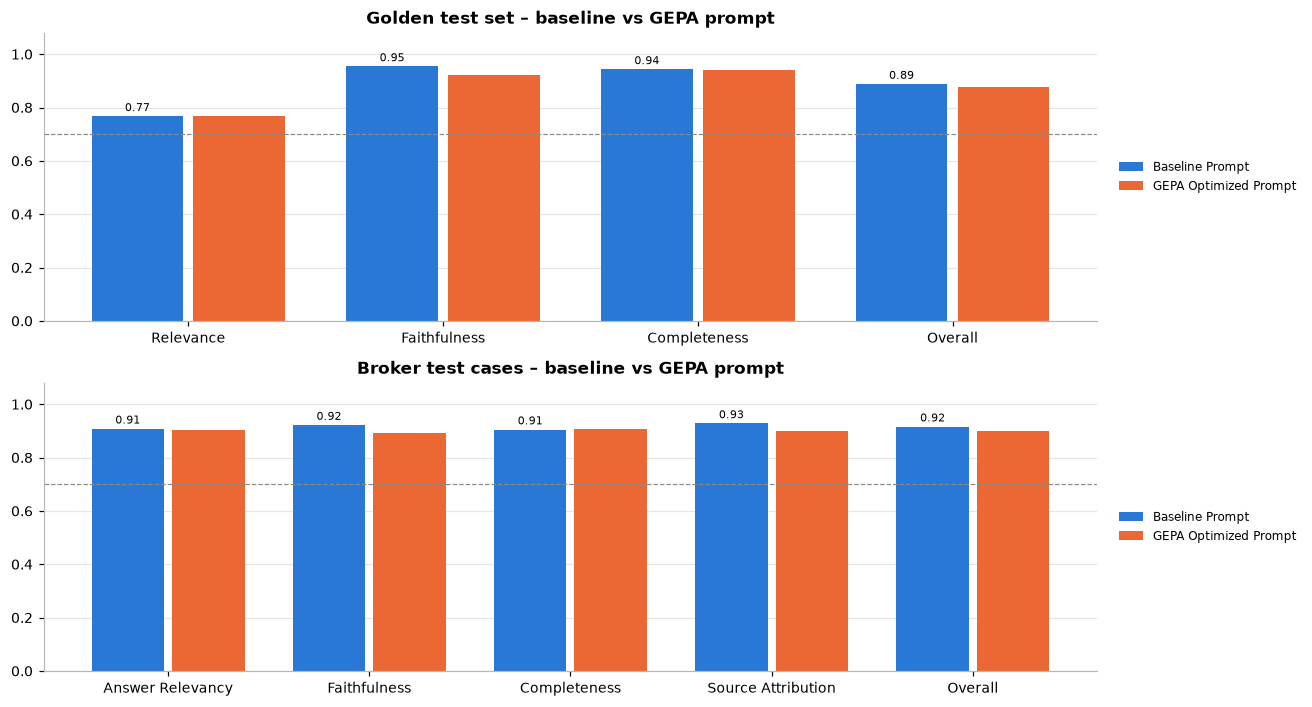

In [41]:
golden_comparison_df = pd.DataFrame([
    summary_row("Baseline Prompt", baseline_test_eval),
    summary_row("GEPA Optimized Prompt", optimized_test_eval),
]).set_index("Pipeline")
case_comparison_df = pd.DataFrame([
    summary_row("Baseline Prompt", baseline_case_eval),
    summary_row("GEPA Optimized Prompt", optimized_case_eval),
]).set_index("Pipeline")

print("Golden test set (reference-based metrics):")
display(golden_comparison_df)
print("Broker test cases (reference-free metrics):")
display(case_comparison_df)


def grouped_bars(ax, df: pd.DataFrame, title: str) -> None:
    """Grouped bar chart: one group per metric, one bar per pipeline."""
    metrics = list(df.columns)
    n = len(df)
    width = 0.8 / n
    x = np.arange(len(metrics))
    for i, (name, row) in enumerate(df.iterrows()):
        bars = ax.bar(x + (i - (n - 1) / 2) * width, row.values, width=width * 0.9, color=PALETTE[i], label=name)
        if name == df["Overall"].idxmax():          # label only the best pipeline to keep the chart readable
            for b in bars:
                ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01, f"{b.get_height():.2f}",
                        ha="center", va="bottom", fontsize=7)
    ax.set_xticks(x, metrics)
    ax.set_ylim(0, 1.08)
    ax.axhline(0.7, color="#8a8984", linewidth=0.8, linestyle="--")
    ax.set_title(title)
    ax.legend(frameon=False, fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))   # outside the plot area


fig, axes = plt.subplots(2, 1, figsize=(12, 6.5))
grouped_bars(axes[0], golden_comparison_df, "Golden test set – baseline vs GEPA prompt")
grouped_bars(axes[1], case_comparison_df, "Broker test cases – baseline vs GEPA prompt")
plt.tight_layout()
plt.show()

##### **NOTE:**

> LLM generation and G-Eval scoring are not fully deterministic, so re-running the notebook can move individual scores by a few hundredths. The comparisons below focus on differences that are larger than that noise.

**Observations – GEPA prompt optimisation**

- GEPA ran 6 mutation attempts in ~10 minutes. Two children were **accepted** by Pareto non-domination (iterations 2 and 4); the others were skipped because they did not beat the parent on the minibatch. Two of the skipped mutations collapsed to a minibatch score of ≈ 0.02 (broken prompts), which shows why the minibatch gate exists: bad mutations are discarded before they reach the Pareto set.
- The selected prompt scored **0.8835 vs 0.8791** for the original on the 4-question Pareto set. It compresses the rules, adds a rule to "directly address each part of the broker's question", and **softens rule 5**: the mandatory statement "this is market intelligence, not personalised investment advice" became "without giving personalised investment advice".
- **On held-out data the optimised prompt did not improve the pipeline:** golden test overall 0.876 vs 0.888 and broker test cases 0.900 vs 0.916, with Faithfulness and Source Attribution slightly lower. The +0.004 gain on the Pareto set is smaller than the judge's run-to-run noise. With only 14 training goldens (4 for Pareto validation) the optimiser over-fits to a handful of questions. In two earlier development runs GEPA kept the original prompt unchanged, which confirms that the gain is not stable.
- **Compliance side-effect:** GEPA optimises only what the metrics measure. None of the metrics rewards the disclaimer, so the optimiser treated it as removable and later answers with the optimised prompt mostly omit it. For a regulated brokerage, compliance requirements must be enforced outside the optimisable prompt or measured explicitly.
- Conclusion: the hand-written, requirements-driven baseline prompt was already close to optimal for this data. GEPA is still valuable as a systematic check, but it needs a larger golden set and compliance-aware metrics before its output should replace a reviewed prompt.

# Section 3: RAG Configuration Tuning and Evaluation

## 3.1 Define the RAG configurations

Three configurations change **retrieval** (chunk size, chunk overlap, number of chunks *k*) and **generation** (temperature, top-p, max tokens) together, each designed around a distinct hypothesis about what brokers need. All three use the GEPA-optimised prompt and the entity-aware retriever, so differences come from the parameters. The baseline settings (1000 / 150, k = 5, temperature 0, top-p 1.0, 900 tokens) are the reference point.

| | Config 1 – Precision | Config 2 – Balanced | Config 3 – Context-rich |
|---|---|---|---|
| chunk size / overlap | 700 / 100 (14 %) | 1200 / 200 (17 %) | 1800 / 300 (17 %) |
| *k* (semantic chunks) | 4 | 6 | 8 |
| temperature | 0.0 | 0.1 | 0.3 |
| top-p | 0.8 | 0.9 | 1.0 |
| max tokens | 600 | 900 | 1300 |
| hypothesis | Small, focused chunks and few of them reduce noise; greedy, tightly truncated sampling and a short answer budget maximise faithfulness for single-fact questions (auditor opinion, a closing price). | One paragraph-plus per chunk keeps a disclosure and its figures together; a moderate *k* covers 2–3 entities; near-deterministic sampling. | Large chunks hold whole statement tables / risk sections and more of them are retrieved, for multi-company, multi-source questions; a little more sampling freedom and a larger budget allow richer synthesis. |
| expected risk | misses context for multi-part questions | – | more distractor text, lower faithfulness, longer answers |

In [42]:
RAG_CONFIGURATIONS = [
    {
        "name": "Config_1_Precision",
        "chunk_size": 700, "chunk_overlap": 100, "k": 4,
        "temperature": 0.0, "top_p": 0.8, "max_tokens": 600,
        "rationale": "Small focused chunks, few retrieved, greedy decoding and a short budget for precise single-fact answers.",
    },
    {
        "name": "Config_2_Balanced",
        "chunk_size": 1200, "chunk_overlap": 200, "k": 6,
        "temperature": 0.1, "top_p": 0.9, "max_tokens": 900,
        "rationale": "Paragraph-sized chunks and moderate k to cover 2-3 entities; near-deterministic generation.",
    },
    {
        "name": "Config_3_Context_Rich",
        "chunk_size": 1800, "chunk_overlap": 300, "k": 8,
        "temperature": 0.3, "top_p": 1.0, "max_tokens": 1300,
        "rationale": "Large chunks and high k for multi-company, multi-source synthesis; more generation freedom.",
    },
]

display(pd.DataFrame(RAG_CONFIGURATIONS).set_index("name"))

# Build (or reuse) one Chroma collection per chunking strategy.
for cfg in RAG_CONFIGURATIONS:
    print(f"{cfg['name']}: ", end="")
    build_vectorstore(cfg["chunk_size"], cfg["chunk_overlap"])

display(pd.DataFrame([
    {"chunk_size / overlap": f"{cs} / {co}", "vectors in collection": store._collection.count()}
    for (cs, co), store in VECTORSTORES.items()
]))

,chunk_size,chunk_overlap,k,temperature,top_p,max_tokens,rationale
name,,,,,,,
Config_1_Precision,700,100,4,0.0,0.8,600,"Small focused chunks, few retrieved, greedy decoding and a short budget for precise single-fact answers."
Config_2_Balanced,1200,200,6,0.1,0.9,900,Paragraph-sized chunks and moderate k to cover 2-3 entities; near-deterministic generation.
Config_3_Context_Rich,1800,300,8,0.3,1.0,1300,"Large chunks and high k for multi-company, multi-source synthesis; more generation freedom."


Config_1_Precision: 

Re-using persisted collection with 12,035 documents
Config_2_Balanced: 

Re-using persisted collection with 7,294 documents
Config_3_Context_Rich: 

Re-using persisted collection with 5,102 documents


,chunk_size / overlap,vectors in collection
0,1000 / 150,8507
1,700 / 100,12035
2,1200 / 200,7294
3,1800 / 300,5102


## 3.2 Create a runtime answering function

In [43]:
def answer_with_rag_config(question: str, config: dict) -> dict:
    """Answer with the GEPA-optimised prompt, the config's own index / k, and its generation settings."""
    store = build_vectorstore(config["chunk_size"], config["chunk_overlap"])   # cached after first build
    docs = retrieve_docs(question, store, k=config["k"])
    context = format_docs(docs)
    final_prompt = gepa_prompt.interpolate(input=question, context=context)

    config_llm = ChatOpenAI(
        model=ANSWER_MODEL,
        temperature=config["temperature"],
        top_p=config["top_p"],
        max_tokens=config["max_tokens"],
        api_key=os.getenv("OPENAI_API_KEY"),
        base_url=os.getenv("OPENAI_BASE_URL"),
    )
    start = time.time()
    response = config_llm.invoke([
        SystemMessage(content=GEPA_SYSTEM_MESSAGE),
        HumanMessage(content=final_prompt),
    ])
    return {"answer": response.content, "docs": docs, "context": context, "latency_s": time.time() - start}

## 3.3 Evaluate one configuration on a benchmark set

In [44]:
def evaluate_rag_configuration(config: dict, goldens_subset, label: str) -> dict:
    """Evaluate one configuration on golden examples (reference-based) and on the broker test cases."""
    print("\n" + "=" * 90)
    print(f"Evaluating: {config['name']} | {label}")
    print("=" * 90)
    answer_fn = lambda q: answer_with_rag_config(q, config)
    golden_eval = evaluate_pipeline_on_goldens(answer_fn, goldens_subset, f"{config['name']} | golden")
    case_eval = evaluate_pipeline_on_test_cases(answer_fn, f"{config['name']} | test cases")
    return {
        "configuration": config["name"],
        "golden_eval": golden_eval,
        "case_eval": case_eval,
        "rationale": config["rationale"],
    }

## 3.4 Run all configurations on the test set

In [45]:
configuration_results = []
start_time = time.time()

for config in RAG_CONFIGURATIONS:
    configuration_results.append(evaluate_rag_configuration(config, test_goldens, "Test Set"))

print(f"\nCompleted all configurations. Execution time: {time.time() - start_time:.0f}s")


Evaluating: Config_1_Precision | Test Set


[Config_1_Precision | golden] 1/6  Relevance: 0.97 | Faithfulness: 1.00 | Completeness: 1.00


[Config_1_Precision | golden] 2/6  Relevance: 0.56 | Faithfulness: 1.00 | Completeness: 1.00


[Config_1_Precision | golden] 3/6  Relevance: 0.61 | Faithfulness: 0.76 | Completeness: 1.00


[Config_1_Precision | golden] 4/6  Relevance: 0.84 | Faithfulness: 1.00 | Completeness: 1.00


[Config_1_Precision | golden] 5/6  Relevance: 0.68 | Faithfulness: 0.93 | Completeness: 0.87


... (24 outputs left out)

[Config_3_Context_Rich | test cases] 2/5  Answer Relevancy: 0.97 | Faithfulness: 0.56 | Completeness: 0.86 | Source Attribution: 0.52


[Config_3_Context_Rich | test cases] 3/5  Answer Relevancy: 0.90 | Faithfulness: 0.90 | Completeness: 0.90 | Source Attribution: 0.90


[Config_3_Context_Rich | test cases] 4/5  Answer Relevancy: 0.90 | Faithfulness: 0.63 | Completeness: 0.92 | Source Attribution: 0.90


[Config_3_Context_Rich | test cases] 5/5  Answer Relevancy: 0.90 | Faithfulness: 0.90 | Completeness: 0.89 | Source Attribution: 0.90

Completed all configurations. Execution time: 378s


**Answers to the broker test cases from each configuration.** The table shows each configuration's answer side by side with its four scores; the full text of every answer is printed below it.

In [46]:
case_answers = pd.DataFrame({
    res["configuration"]: res["case_eval"]["details"].set_index("id")["answer"]
    for res in configuration_results
})
case_scores = pd.concat({
    res["configuration"]: res["case_eval"]["details"].set_index("id")[[m.name for m in TEST_CASE_METRICS]]
    for res in configuration_results
}, axis=1).round(2)
display(case_scores)

for case in final_test_cases:
    display(Markdown(f"---\n### Test case {case['id']}\n**Question:** {case['question'].replace('$', chr(92) + '$')}"))
    for res in configuration_results:
        row = res["case_eval"]["details"].set_index("id").loc[case["id"]]
        scores = ", ".join(f"{m.name} {row[m.name]:.2f}" for m in TEST_CASE_METRICS)
        display(Markdown(f"**{res['configuration']}** — *{scores} · {row['answer_words']} words · {row['latency_s']:.1f}s*"))
        show_markdown(row["answer"])

Config_1_Precision                                              Config_2_Balanced                                              Config_3_Context_Rich                                             
     Answer Relevancy Faithfulness Completeness Source Attribution  Answer Relevancy Faithfulness Completeness Source Attribution      Answer Relevancy Faithfulness Completeness Source Attribution
id                                                                                                                                                                                                  
1                0.84         0.81         0.75               0.67              0.86         0.90         0.78               0.89                  0.89         0.81         0.83               0.62
2                0.90         0.97         0.95               0.98              0.95         0.98         0.96               0.99                  0.97         0.56         0.86               0.52
3                0.88         0.93         0.90               0.99              0.88         0.90         0.90               0.91                  0.90         0.90         0.90               0.90
4                0.90         0.86         0.91               0.90              0.90         0.80         0.91               0.87                  0.90         0.63         0.92               0.90
5                0.87         0.90         0.83               0.90              0.90         0.92         0.89               0.90                  0.90         0.90         0.89               0.90

---
### Test case 1
**Question:** Compare the total revenue and net income reported by Apple, Amazon, and Alphabet in their latest 10-Q filings. Which company grew fastest year-over-year?

**Config_1_Precision** — *Answer Relevancy 0.84, Faithfulness 0.81, Completeness 0.75, Source Attribution 0.67 · 184 words · 3.3s*

### Latest 10-Q Revenue and Net Income Comparison

**Apple Inc. (AAPL)**  
- **Total Revenue**: \$143,756 million for the three months ended December 27, 2025  
- **Net Income**: Not explicitly stated in the retrieved context.  

**Amazon.com, Inc. (AMZN)**  
- **Total Revenue**: \$158,877 million for the three months ended September 30, 2025  
- **Net Income**: \$15,328 million for the three months ended September 30, 2025  

**Alphabet Inc. (GOOGL)**  
- **Total Revenue**: \$102,300 million for the three months ended September 30, 2025  
- **Net Income**: Not explicitly stated in the retrieved context.  

### Year-over-Year Growth Comparison
- **Apple**: Revenue increased from \$124,300 million (December 28, 2024) to \$143,756 million (December 27, 2025), a growth of **16%**.
- **Amazon**: Revenue decreased from \$180,169 million (September 30, 2024) to \$158,877 million (September 30, 2025), a decline of **11.8%**.
- **Alphabet**: Revenue increased from \$88,300 million (September 30, 2024) to \$102,300 million (September 30, 2025), a growth of **16%**.

### Fastest Growing Company
Both **Apple** and **Alphabet** grew at **16%** year-over-year, while **Amazon** experienced a decline. Therefore, Apple and Alphabet are tied for the fastest growth among the three companies.

**Config_2_Balanced** — *Answer Relevancy 0.86, Faithfulness 0.90, Completeness 0.78, Source Attribution 0.89 · 189 words · 4.4s*

### Comparison of Total Revenue and Net Income

**1. Apple Inc. (AAPL)**
- **Total Revenue (Q1 2026)**: \$143,756 million (for the three months ended December 27, 2025) [S2][S4].
- **Net Income (Q1 2026)**: Not explicitly stated in the retrieved context.

**2. Amazon.com, Inc. (AMZN)**
- **Total Revenue (Q3 2025)**: \$180,169 million (for the three months ended September 30, 2025) [S11][S12].
- **Net Income (Q3 2025)**: \$21,187 million [S11][S13].

**3. Alphabet Inc. (GOOGL)**
- **Total Revenue (Q3 2025)**: \$102,346 million (for the three months ended September 30, 2025) [S17][S19].
- **Net Income (Q3 2025)**: \$34,979 million [S17][S19].

### Year-over-Year Growth Comparison
- **Apple Inc.**: Revenue growth of 16% from Q1 2025 to Q1 2026 [S2].
- **Amazon.com**: Revenue growth of 13.4% from Q3 2024 to Q3 2025 (from \$158,877 million to \$180,169 million) [S11][S12].
- **Alphabet Inc.**: Revenue growth of 16% from Q3 2024 to Q3 2025 (from \$88,268 million to \$102,346 million) [S19].

### Fastest Growing Company
- **Apple Inc.** and **Alphabet Inc.** both achieved a revenue growth rate of **16%** year-over-year, while **Amazon.com** grew at **13.4%**. Therefore, Apple and Alphabet grew the fastest year-over-year in terms of revenue.

... (26 outputs left out)

**Config_2_Balanced** — *Answer Relevancy 0.90, Faithfulness 0.92, Completeness 0.89, Source Attribution 0.90 · 363 words · 5.6s*

### Investment Overview: Google, Amazon, and Apple in AI

#### 1. **Performance Summary**
- **Google (Alphabet Inc.)**: 
  - Price increased from **\$252.74** on **2025-10-23** to **\$339.32** on **2026-04-22** (+34.3%). Last 30-day change: **+12.3%**. Recent close on **2026-04-22** was **\$339.32** [S7].
  
- **Amazon (Amazon.com, Inc.)**: 
  - Price rose from **\$221.09** on **2025-10-23** to **\$255.36** on **2026-04-22** (+15.5%). Last 30-day change: **+21.5%**. Recent close on **2026-04-22** was **\$255.36** [S12].
  
- **Apple (Apple Inc.)**: 
  - Price moved from **\$259.09** on **2025-10-23** to **\$273.17** on **2026-04-22** (+5.4%). Last 30-day change: **+8.6%**. Recent close on **2026-04-22** was **\$273.17** [S17].

#### 2. **AI Business Insights**
- **Google**: 
  - Emphasizes a full-stack approach to AI, integrating advanced AI capabilities across its products and services. They are developing frontier generative AI models and have centralized AI-related R&D. Google aims to monetize AI differently than traditional offerings, focusing on user experience first [S2][S3][S5].
  
- **Amazon**: 
  - Plans to increase spending on technology and infrastructure to support AI initiatives, which may impact short-term cash flow but is aimed at long-term growth. They are focused on enhancing user experience through AI and machine learning [S11]. Recent upgrades from analysts suggest confidence in AWS growth, which is expected to accelerate [S14].
  
- **Apple**: 
  - Faces significant patent claims related to AI and machine learning technologies, which could impact operations. They are integrating AI into their products but are also navigating legal challenges that could affect their innovation pace [S16][S19].

#### 3. **Market Sentiment**
- **Google**: Recent stock dip of **0.57%** as investors await Q1 earnings, reflecting cautious sentiment amid high AI spending [S9].
  
- **Amazon**: Positive sentiment with double upgrades from analysts ahead of earnings, indicating confidence in future growth [S14].
  
- **Apple**: Mixed sentiment due to ongoing legal challenges, but still a strong player in the tech space [S19].

### Conclusion
- **Best Performer**: Google shows strong price growth and a robust AI strategy, but faces competitive risks.
- **Amazon**: Gaining momentum with analyst upgrades and a focus on AI, but still lower growth compared to Google.
- **Apple**: Slower growth and legal challenges may hinder its AI advancements.

Consider these factors when evaluating which company aligns best with your investment strategy in AI.

**Config_3_Context_Rich** — *Answer Relevancy 0.90, Faithfulness 0.90, Completeness 0.89, Source Attribution 0.90 · 349 words · 5.3s*

### Investment Overview in AI: Google, Amazon, and Apple

#### 1. **Performance Summary**
- **Google (Alphabet Inc.)**: 
  - Price increased from **\$252.74** on **October 23, 2025** to **\$339.32** on **April 22, 2026** (+34.3%). Last 30 days: +12.3% [S9].
  
- **Amazon**: 
  - Price rose from **\$221.09** on **October 23, 2025** to **\$255.36** on **April 22, 2026** (+15.5%). Last 30 days: +21.5% [S14].
  
- **Apple**: 
  - Price moved from **\$259.09** on **October 23, 2025** to **\$273.17** on **April 22, 2026** (+5.4%). Last 30 days: +8.6% [S19].

#### 2. **AI Business Insights**
- **Google**: 
  - Emphasizes a bold yet responsible approach to AI, integrating it into core products and services, such as Google Cloud and Search. Investments in AI are viewed as essential for future growth, with significant focus on user engagement and monetization strategies [S2][S4]. The company has invested over **\$200 billion** in R&D over the last five years [S5].
  
- **Amazon**: 
  - Plans to increase spending on technology and infrastructure to support AI initiatives, particularly in AWS. They anticipate that advancements in AI will enhance user experiences and operational efficiencies [S12]. However, they face risks related to competition and the adoption of new technologies [S13].
  
- **Apple**: 
  - Faces litigation risks associated with integrating AI and machine learning into its products. The company is focused on defending its intellectual property while navigating the competitive landscape of emerging technologies [S17]. There is less specific commentary on their AI strategy compared to Google and Amazon.

#### 3. **Market Sentiment and Buzz**
- **Google**: Recent stock dip of **0.57%** as investors await Q1 earnings, reflecting concerns over AI spending [S11].
  
- **Amazon**: Received upgrades from BofA and KeyBanc, with expectations of AWS growth accelerating, indicating positive market sentiment ahead of earnings [S16].
  
- **Apple**: Current news focuses on leadership changes rather than AI developments, which may affect investor sentiment [S21].

### Conclusion
- **Best Bet**: Based on performance and AI integration strategies, **Google** appears to be leading in AI innovation and investment, but **Amazon** shows strong momentum with recent upgrades. **Apple** is more cautious, facing litigation risks that could impact its AI initiatives.

## 3.5 Compare configurations

In [47]:
def approach_row(name: str, golden_eval: dict, case_eval: dict, rationale: str) -> dict:
    """One comparison row: golden metrics, test-case metrics, composite score and efficiency."""
    golden_means, case_means = golden_eval["metric_means"], case_eval["metric_means"]
    return {
        "Approach": name,
        "Relevance (golden)": golden_means["Relevance"],
        "Faithfulness (golden)": golden_means["Faithfulness"],
        "Completeness (golden)": golden_means["Completeness"],
        "Golden Overall": golden_eval["overall_mean"],
        "Answer Relevancy (cases)": case_means["Answer Relevancy"],
        "Faithfulness (cases)": case_means["Faithfulness"],
        "Completeness (cases)": case_means["Completeness"],
        "Source Attribution (cases)": case_means["Source Attribution"],
        "Test-case Overall": case_eval["overall_mean"],
        # Composite: equal weight to benchmark accuracy and real broker-question quality.
        "Composite Score": round((golden_eval["overall_mean"] + case_eval["overall_mean"]) / 2, 3),
        "Avg latency (s)": round(float(case_eval["details"]["latency_s"].mean()), 1),
        "Avg answer words": int(case_eval["details"]["answer_words"].mean()),
        "Rationale": rationale,
    }


all_results = [
    approach_row("Baseline Prompt", baseline_test_eval, baseline_case_eval,
                 "Baseline prompt, 1000/150 chunks, k=5, temperature 0 (Section 1)."),
    approach_row("GEPA Optimized Prompt", optimized_test_eval, optimized_case_eval,
                 "GEPA prompt with the baseline retrieval and generation settings (Section 2)."),
]
for res in configuration_results:
    all_results.append(approach_row(res["configuration"], res["golden_eval"], res["case_eval"], res["rationale"]))

# Rank by composite score; composites within 0.01 of each other are treated as ties (smaller than
# the run-to-run noise of the judge) and broken by test-case Faithfulness – grounding comes first
# in a compliance-sensitive broker tool.
results_df = (pd.DataFrame(all_results)
              .assign(_composite_band=lambda d: (d["Composite Score"] * 100).round())
              .sort_values(["_composite_band", "Faithfulness (cases)"], ascending=False)
              .drop(columns="_composite_band")
              .reset_index(drop=True))

print("Comparison of all approaches (sorted by composite score):")
display(results_df.drop(columns="Rationale").set_index("Approach"))

Comparison of all approaches (sorted by composite score):


,Relevance (golden),Faithfulness (golden),Completeness (golden),Golden Overall,Answer Relevancy (cases),Faithfulness (cases),Completeness (cases),Source Attribution (cases),Test-case Overall,Composite Score,Avg latency (s),Avg answer words
Approach,,,,,,,,,,,,
Baseline Prompt,0.767,0.954,0.943,0.888,0.908,0.922,0.905,0.928,0.916,0.902,3.5,220
Config_2_Balanced,0.773,0.943,0.966,0.894,0.900,0.899,0.890,0.913,0.901,0.897,4.0,227
Config_1_Precision,0.757,0.949,0.978,0.895,0.881,0.895,0.871,0.888,0.884,0.889,3.6,211
GEPA Optimized Prompt,0.767,0.921,0.939,0.876,0.902,0.891,0.906,0.899,0.900,0.888,3.5,203
Config_3_Context_Rich,0.780,0.913,0.977,0.890,0.910,0.760,0.880,0.767,0.829,0.859,3.9,226


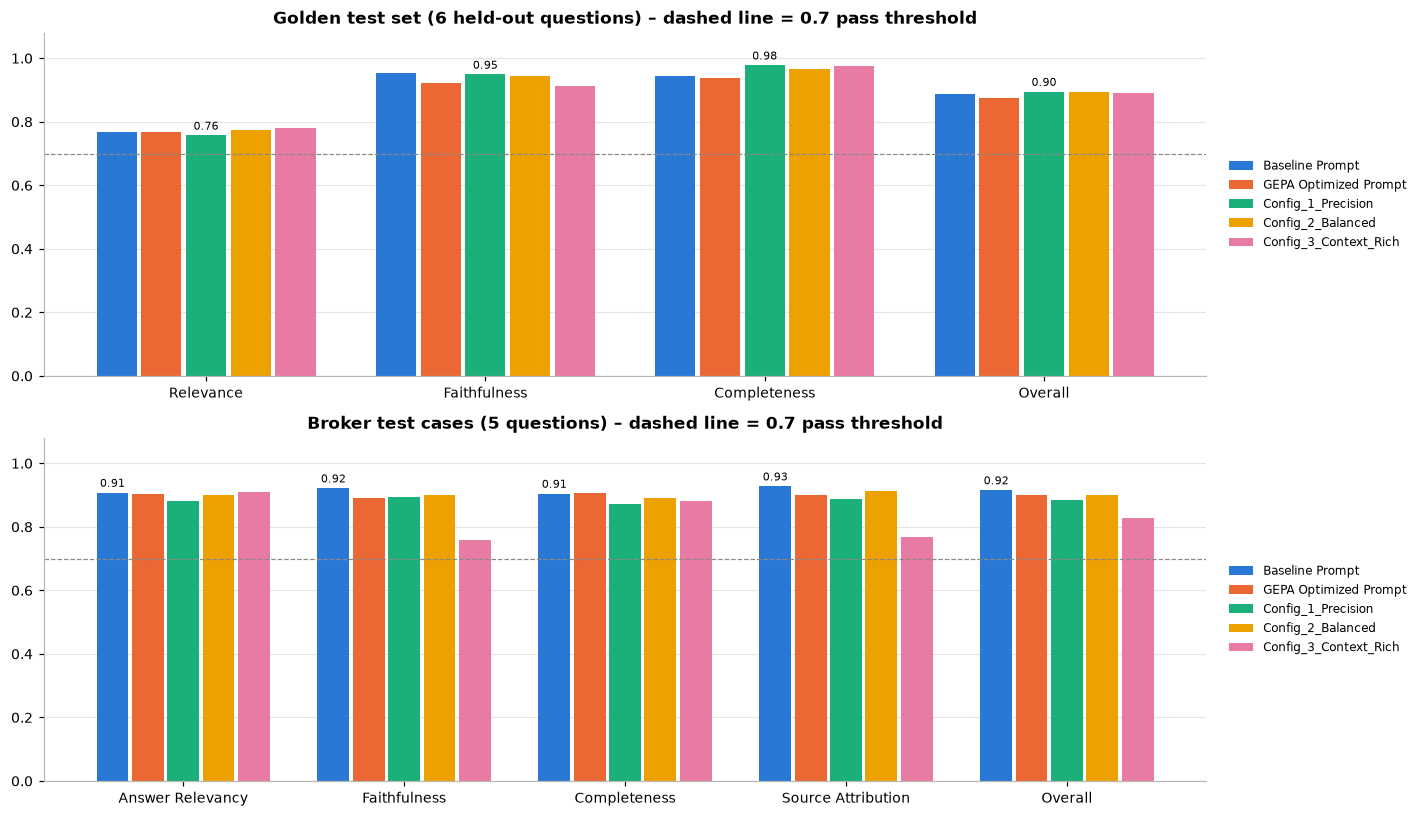

In [48]:
plot_order = ["Baseline Prompt", "GEPA Optimized Prompt"] + [c["name"] for c in RAG_CONFIGURATIONS]
indexed = results_df.set_index("Approach").loc[plot_order]

golden_plot = indexed[["Relevance (golden)", "Faithfulness (golden)", "Completeness (golden)", "Golden Overall"]]
golden_plot.columns = ["Relevance", "Faithfulness", "Completeness", "Overall"]
case_plot = indexed[["Answer Relevancy (cases)", "Faithfulness (cases)", "Completeness (cases)",
                     "Source Attribution (cases)", "Test-case Overall"]]
case_plot.columns = ["Answer Relevancy", "Faithfulness", "Completeness", "Source Attribution", "Overall"]

fig, axes = plt.subplots(2, 1, figsize=(13, 7.5))
grouped_bars(axes[0], golden_plot, "Golden test set (6 held-out questions) – dashed line = 0.7 pass threshold")
grouped_bars(axes[1], case_plot, "Broker test cases (5 questions) – dashed line = 0.7 pass threshold")
plt.tight_layout()
plt.show()

## 3.6 Select the best overall approach

**Selection rule.** As the Section 4 title requires, the production pipeline must use the **optimised prompt**, so the candidates are the GEPA prompt with the default settings and the three tuned configurations; the baseline row stays in the table as the reference point. Among the candidates, the best approach is the one with the highest **composite score** = average of the golden-test overall score (accuracy against reference answers) and the broker test-case overall score (relevance, grounding, completeness and citations on realistic, open-ended broker questions). Using both protects against picking a configuration that only fits the short golden answers. Composite scores within 0.01 of each other are within the judge's run-to-run noise, so such ties are broken by test-case **Faithfulness**, the metric that matters most for compliance.

In [49]:
# Deployable candidates use the optimised prompt; the baseline is a reference only.
deployable = results_df[results_df["Approach"] != "Baseline Prompt"]
best_approach_name = deployable.iloc[0]["Approach"]
print("Ranking of deployable approaches:", deployable["Approach"].tolist())

BEST_FINAL_APPROACH = next(item for item in all_results if item["Approach"] == best_approach_name)

print("Best approach selected:", best_approach_name)
print(json.dumps({k: v for k, v in BEST_FINAL_APPROACH.items()}, indent=2))

Ranking of deployable approaches: ['Config_2_Balanced', 'Config_1_Precision', 'GEPA Optimized Prompt', 'Config_3_Context_Rich']
Best approach selected: Config_2_Balanced
{
  "Approach": "Config_2_Balanced",
  "Relevance (golden)": 0.773,
  "Faithfulness (golden)": 0.943,
  "Completeness (golden)": 0.966,
  "Golden Overall": 0.894,
  "Answer Relevancy (cases)": 0.9,
  "Faithfulness (cases)": 0.899,
  "Completeness (cases)": 0.89,
  "Source Attribution (cases)": 0.913,
  "Test-case Overall": 0.901,
  "Composite Score": 0.897,
  "Avg latency (s)": 4.0,
  "Avg answer words": 227,
  "Rationale": "Paragraph-sized chunks and moderate k to cover 2-3 entities; near-deterministic generation."
}


## 3.7 Save the tuning results

In [50]:
results_output_path = ARTIFACT_DIR / "rag_configuration_results.csv"
results_df.to_csv(results_output_path, index=False)

# Per-question scores and judge reasons for every approach (audit trail).
per_question = []
for name, ev in [("Baseline Prompt", baseline_test_eval), ("Baseline Prompt", baseline_case_eval),
                 ("GEPA Optimized Prompt", optimized_test_eval), ("GEPA Optimized Prompt", optimized_case_eval)]:
    per_question.append(ev["details"].assign(approach=name, eval_set=ev["label"]))
for res in configuration_results:
    for ev in (res["golden_eval"], res["case_eval"]):
        per_question.append(ev["details"].assign(approach=res["configuration"], eval_set=ev["label"]))
per_question_path = ARTIFACT_DIR / "per_question_scores.csv"
pd.concat(per_question, ignore_index=True).to_csv(per_question_path, index=False)

best_approach_path = ARTIFACT_DIR / "best_final_approach.json"
with open(best_approach_path, "w", encoding="utf-8") as f:
    json.dump({"best_approach": BEST_FINAL_APPROACH,
               "best_configuration": next((c for c in RAG_CONFIGURATIONS if c["name"] == best_approach_name), None),
               "optimized_prompt": gepa_prompt.text_template,
               "all_results": all_results}, f, indent=2, ensure_ascii=False)

print(f"Saved configuration comparison to : {results_output_path}")
print(f"Saved per-question scores to      : {per_question_path}")
print(f"Saved best approach + prompt to   : {best_approach_path}")

Saved configuration comparison to : artifacts/rag_configuration_results.csv
Saved per-question scores to      : artifacts/per_question_scores.csv
Saved best approach + prompt to   : artifacts/best_final_approach.json


##### **NOTE:**

> Scores can move by a few hundredths between runs because generation (for configurations with temperature > 0) and G-Eval judging are probabilistic; the observations focus on the larger, consistent patterns.

**Observations – RAG configuration tuning**

| Approach | Golden overall | Test-case overall | Composite |
|---|---|---|---|
| Baseline Prompt (reference) | 0.888 | **0.916** | **0.902** |
| **Config_2_Balanced** (selected) | 0.894 | 0.901 | 0.897 |
| Config_1_Precision | **0.895** | 0.884 | 0.889 |
| GEPA Optimized Prompt (default settings) | 0.876 | 0.900 | 0.888 |
| Config_3_Context_Rich | 0.890 | 0.829 | 0.859 |

- **Config_2_Balanced (1200 / 200, k = 6, T = 0.1, top-p 0.9, 900 tokens) is the best deployable configuration** and is statistically tied with the baseline (0.897 vs 0.902, within the judge's noise). It is the **only one of the five approaches that answered test case 1 completely correctly** (the baseline and GEPA answers both used Apple's June quarter and Amazon's prior-year net income): Apple's latest quarter (\$143,756M, +16 %), Amazon \$180,169M revenue and \$21,187M net income, Alphabet \$102,346M and \$34,979M. Paragraph-sized chunks keep a statement table's header and its rows together, so the model can match each number to the right period. It also has the best Source Attribution of the three configurations (0.913).
- **Config_1_Precision (700 / 100, k = 4, T = 0, top-p 0.8, 600 tokens)** has the best golden-test overall (0.895, Faithfulness 0.949) – small chunks are precise for single-fact questions. It is the weakest on multi-part broker questions (Completeness 0.871). Small chunks cut financial tables apart: in test case 1 it swapped Amazon's 2024 / 2025 columns and reported a revenue *decline* of 11.8 %. The 600-token budget also **truncated** the AI-comparison answer mid-sentence.
- **Config_3_Context_Rich (1800 / 300, k = 8, T = 0.3, top-p 1.0, 1300 tokens)** has the highest golden Relevance (0.780) and Completeness (0.977): more context helps it match reference answers. It is the **least faithful** on broker questions (Faithfulness 0.760, Source Attribution 0.767), with real errors:
  - in test case 1 it reported Apple's June-2025 quarter instead of the latest one;
  - in test case 4 it described the −29.3 % first-to-last change as the decline from the \$116k high to the \$60k low.

  Part of the gap is **judge noise**: in test case 2 its Amazon low (\$196.00, 17 Feb 2026) and high (\$258.60, 3 Nov 2025) were checked against the price data and are correct and present in the cited source, yet scored Faithfulness 0.56. The direction of the finding holds (more context did not help on broker questions), but the size of the gap should be read with that caveat.
- Every approach passes every metric's 0.7 threshold on average. Differences between the top four approaches (0.888 – 0.902) are small, so the factual check of test case 1 and the faithfulness of multi-source answers are the decisive qualitative evidence.
- **Efficiency:** average latency is 3.5 – 4.0 seconds and answers are 200 – 230 words for all approaches. Any of them fits a pre-call workflow; the choice can be made on quality alone.
- Across all experiments, **data preparation and retrieval design (entity boost, recency filter, chunk size) mattered more than prompt or sampling parameters.** The biggest quality differences came from what the model was given to read.

# Section 4: Final RAG Inference Pipeline with the Optimized Prompt and Best RAG Configuration

## 4.1 Define the final inference helper

In [51]:
def answer_final_question(question: str) -> dict:
    """Answer with the best approach selected in Section 3.6 (baseline, GEPA prompt, or a tuned configuration)."""
    name = BEST_FINAL_APPROACH["Approach"]
    if name == "Baseline Prompt":
        result = baseline_answer(question)
    elif name == "GEPA Optimized Prompt":
        result = optimized_prompt_answer(question)
    else:
        config = next(cfg for cfg in RAG_CONFIGURATIONS if cfg["name"] == name)
        result = answer_with_rag_config(question, config)
    return {"question": question, "approach": name, **result}


print("Final pipeline uses:", BEST_FINAL_APPROACH["Approach"])

Final pipeline uses: Config_2_Balanced


## 4.2 Define the final test cases

The five broker test cases defined in Section 1.4, re-stated here as in the template:

In [52]:
final_test_cases = [
    {
        "id": 1,
        "question": (
            "Compare the total revenue and net income reported by Apple, Amazon, "
            "and Alphabet in their latest 10-Q filings. Which company grew fastest "
            "year-over-year?"
        )
    },
    {
        "id": 2,
        "question": (
            "Based on this week's news sentiment around Amazon, would you classify "
            "the current signal as bullish or bearish, and does the price data support that?"
        )
    },
    {
        "id": 3,
        "question": (
            "Should I invest in Apple right now? I heard Tim Cook is stepping down — "
            "is that a red flag? How's the stock been doing, and is there anything I should "
            "be worried about with the company's financials or risks?"
        )
    },
    {
        "id": 4,
        "question": (
            "Is now a good time to buy Bitcoin? News is saying it just crossed $78k — "
            "am I too late? What's the price trend looked like over the last few months, "
            "and what's driving the current rally?"
        )
    },
    {
        "id": 5,
        "question": (
            "I want to invest in AI. Out of Google, Amazon, and Apple, which one looks "
            "like the best bet right now? How are they performing, what are they saying "
            "about their AI business, and what's the buzz around them?"
        )
    },
]

## 4.3 Run the final test cases

In [53]:
final_results = []
for item in final_test_cases:
    result = answer_final_question(item["question"])
    display_result(item["id"], item["question"], result)
    final_results.append(result)

---
### Test case 1
**Question:** Compare the total revenue and net income reported by Apple, Amazon, and Alphabet in their latest 10-Q filings. Which company grew fastest year-over-year?

### Latest 10-Q Revenue and Net Income Comparison

**Apple Inc. (AAPL)**  
- **Total Revenue (Q1 2026)**: \$143,756 million  
- **Net Income (Q1 2026)**: Not explicitly stated in the retrieved context.  

**Amazon.com, Inc. (AMZN)**  
- **Total Revenue (Q3 2025)**: \$180,169 million  
- **Net Income (Q3 2025)**: \$21,187 million  

**Alphabet Inc. (GOOGL)**  
- **Total Revenue (Q3 2025)**: \$102,346 million  
- **Net Income (Q3 2025)**: \$34,979 million  

### Year-over-Year Growth Comparison
- **Apple**: Revenue growth from Q1 2025 (\$124,300 million) to Q1 2026 (\$143,756 million) = **16%** increase.
- **Amazon**: Revenue growth from Q3 2024 (\$158,877 million) to Q3 2025 (\$180,169 million) = **13.4%** increase.
- **Alphabet**: Revenue growth from Q3 2024 (\$88,268 million) to Q3 2025 (\$102,346 million) = **16%** increase.

### Fastest Growing Company
Both **Apple** and **Alphabet** grew at **16%** year-over-year, while **Amazon** grew at **13.4%**. Therefore, **Apple and Alphabet** are tied for the fastest growth among the three companies.

*Retrieved 22 documents · generated in 3.4s*

tag,type,source
S1,sec_filing,"SEC 10-K – Apple Inc. (AAPL), period ended 2024-09-28, Item 7 - MD&A"
S2,sec_filing,"SEC 10-Q – Apple Inc. (AAPL), period ended 2025-12-27, Item 2 - MD&A"
S3,sec_filing,"SEC 10-K – Apple Inc. (AAPL), period ended 2024-09-28, Item 8 - Financial Statements"
S4,sec_filing,"SEC 10-Q – Apple Inc. (AAPL), period ended 2025-12-27, Item 2 - MD&A"
S5,sec_filing,"SEC 10-Q – Apple Inc. (AAPL), period ended 2025-06-28, Item 2 - MD&A"
S6,sec_filing,"SEC 10-K – Alphabet Inc. (GOOGL), period ended 2025-12-31, Item 7 - MD&A"
S7,sec_filing,"SEC 10-Q – Apple Inc. (AAPL), period ended 2025-12-27, Item 1 - Financial Statements / Legal Proceedings"
S8,price,"Price data – Apple (NASDAQ) (AAPL), 2025-10-23 to 2026-04-22"
S9,price,"Price data – Apple (NASDAQ) (AAPL), 2025-10"
S10,news,"News – ""5 stats that explain Apple's stock-market dominance during the Tim Cook era"" (Business Insider, 2026-04-22) https://www.businessinsider.com/apple-stock-price-returns-explained-under-ceo-tim-cook-buybacks-2026-4"


---
### Test case 2
**Question:** Based on this week's news sentiment around Amazon, would you classify the current signal as bullish or bearish, and does the price data support that?

**Current Signal Classification: Bullish**

1. **News Sentiment**: Amazon received a double upgrade from BofA and KeyBanc ahead of its Q1 earnings report, with price targets raised to \$298 and \$325, respectively. This indicates positive sentiment and expectations for growth in AWS (Amazon Web Services) accelerating to 28-30% from Q4's 24% [S2].

2. **Price Data**: 
   - The price of Amazon (AMZN) has shown a significant upward trend, moving from a close of **221.09** on **2025-10-23** to **255.36** on **2026-04-22**, representing a **+15.5%** increase over this period. 
   - The last 30 days have seen a **+21.5%** change, indicating strong recent performance.
   - The most recent closing prices are **249.91** on **2026-04-21** and **255.36** on **2026-04-22**, suggesting a positive momentum leading into earnings [S1].

**Conclusion**: The combination of bullish news sentiment and strong price performance supports a bullish classification for Amazon at this time.

... (10 outputs left out)

---
### Test case 5
**Question:** I want to invest in AI. Out of Google, Amazon, and Apple, which one looks like the best bet right now? How are they performing, what are they saying about their AI business, and what's the buzz around them?

### Investment Overview: Google, Amazon, and Apple in AI

#### 1. **Performance Summary**
- **Google (Alphabet Inc.)**: 
  - Price increased from **\$252.74** on **2025-10-23** to **\$339.32** on **2026-04-22** (+34.3%). Last 30-day change: **+12.3%**. Recent close on **2026-04-22** was **\$339.32** [S7].
  
- **Amazon**: 
  - Price moved from **\$221.09** on **2025-10-23** to **\$255.36** on **2026-04-22** (+15.5%). Last 30-day change: **+21.5%**. Recent close on **2026-04-22** was **\$255.36** [S12].
  
- **Apple**: 
  - Price rose from **\$259.09** on **2025-10-23** to **\$273.17** on **2026-04-22** (+5.4%). Last 30-day change: **+8.6%**. Recent close on **2026-04-22** was **\$273.17** [S17].

#### 2. **AI Business Insights**
- **Google**: 
  - Emphasizes a full-stack approach to AI, integrating it across products like Search and YouTube. They are developing frontier generative AI models and investing heavily in AI infrastructure, which they believe will enhance user engagement and revenue growth [S2][S3][S5]. However, they face significant competition and high operational costs [S2].

- **Amazon**: 
  - Plans to increase spending on technology and infrastructure to support AI initiatives, which may impact short-term cash flow but is aimed at long-term growth. They are focusing on enhancing user experience through AI and machine learning [S11]. Recent upgrades from analysts suggest confidence in their growth trajectory, particularly in AWS [S14].

- **Apple**: 
  - Faces risks related to patent claims as it integrates AI into its products. The company is focused on maintaining its competitive edge in technology and innovation, but litigation risks could impact operations [S16]. There is no specific recent commentary on their AI strategy in the provided context.

#### 3. **Market Buzz**
- **Google**: Recent stock dip of **0.57%** as investors await Q1 earnings, reflecting concerns over AI spending [S9].
  
- **Amazon**: Positive sentiment with double upgrades from analysts ahead of earnings, indicating strong expectations for AWS growth [S14].
  
- **Apple**: No significant recent buzz regarding AI specifically, but ongoing leadership changes may affect investor sentiment [S19].

### Conclusion
- **Best Performer**: Google shows strong price growth and a robust AI strategy, but faces competitive pressures. 
- **Amazon** has positive analyst sentiment and is investing heavily in AI, making it a strong contender.
- **Apple** has a stable performance but is facing litigation risks and lacks recent AI-specific commentary.

Consider these factors when evaluating which company aligns best with your investment strategy in AI.

*Retrieved 19 documents · generated in 5.6s*

tag,type,source
S1,news,"News – ""The 3 Best Artificial Intelligence (AI) Growth Stocks to Buy on the Nasdaq Before Q1 Earnings Season"" (Yahoo Entertainment, 2026-04-21) https://consent.yahoo.com/v2/collectConsent?sessionId=1_cc-session_cf89236a-1c21-4229-9f09-b478158d51c6"
S2,sec_filing,"SEC 10-K – Alphabet Inc. (GOOGL), period ended 2025-12-31, Item 1A - Risk Factors"
S3,sec_filing,"SEC 10-K – Alphabet Inc. (GOOGL), period ended 2025-12-31, Item 1 - Business"
S4,sec_filing,"SEC 10-K – Alphabet Inc. (GOOGL), period ended 2025-12-31, Item 1 - Business"
S5,sec_filing,"SEC 10-K – Alphabet Inc. (GOOGL), period ended 2025-12-31, Item 7 - MD&A"
S6,sec_filing,"SEC 10-K – Alphabet Inc. (GOOGL), period ended 2024-12-31, Item 1 - Business"
S7,price,"Price data – Alphabet (NASDAQ) (GOOGL), 2025-10-23 to 2026-04-22"
S8,price,"Price data – Alphabet (NASDAQ) (GOOGL), 2026-01"
S9,news,"News – ""Alphabet Stock Dips 0.57% as Investors Await Q1 Earnings Amid Massive AI Spending Push"" (Ibtimes.com.au, 2026-04-20) https://www.ibtimes.com.au/alphabet-stock-dips-057-investors-await-q1-earnings-amid-massive-ai-spending-push-1867086"
S10,sec_filing,"SEC 10-K – Amazon.com, Inc. (AMZN), period ended 2024-12-31, Item 1A - Risk Factors"


In [54]:
# Final quality check of the production answers with the broker test-case metrics.
final_answers_by_question = {r["question"]: r for r in final_results}
final_case_eval = evaluate_answers(lambda q: final_answers_by_question[q], final_test_cases,
                                   TEST_CASE_METRICS, "Final pipeline")

display(final_case_eval["details"][["id"] + [m.name for m in TEST_CASE_METRICS] + ["n_docs", "answer_words", "latency_s"]]
        .round(2).set_index("id"))
print("Metric means:", final_case_eval["metric_means"], "| overall:", final_case_eval["overall_mean"])

pd.DataFrame([{"id": r_id, "question": r["question"], "answer": r["answer"], "approach": r["approach"],
               "sources": " | ".join(source_label(d) for d in r["docs"])}
              for r_id, r in zip([c["id"] for c in final_test_cases], final_results)]
             ).to_csv(ARTIFACT_DIR / "final_test_case_answers.csv", index=False)
print("Transient gateway 401s recovered during the run:", GATEWAY_RETRY_STATS["transient_401"])
print("G-Eval scores clipped to [0, 1] during the run:", SCORE_CLIP_LOG or "none")

[Final pipeline] 1/5  Answer Relevancy: 0.89 | Faithfulness: 0.84 | Completeness: 0.78 | Source Attribution: 0.78


[Final pipeline] 2/5  Answer Relevancy: 0.93 | Faithfulness: 0.97 | Completeness: 0.97 | Source Attribution: 0.99


[Final pipeline] 3/5  Answer Relevancy: 0.90 | Faithfulness: 0.93 | Completeness: 0.91 | Source Attribution: 0.94


[Final pipeline] 4/5  Answer Relevancy: 0.90 | Faithfulness: 0.70 | Completeness: 0.91 | Source Attribution: 0.91


[Final pipeline] 5/5  Answer Relevancy: 0.89 | Faithfulness: 0.88 | Completeness: 0.88 | Source Attribution: 0.90


,Answer Relevancy,Faithfulness,Completeness,Source Attribution,n_docs,answer_words,latency_s
id,,,,,,,
1,0.89,0.84,0.78,0.78,22,150,3.37
2,0.93,0.97,0.97,0.99,6,141,2.45
3,0.90,0.93,0.91,0.94,8,210,3.22
4,0.90,0.70,0.91,0.91,8,189,2.64
5,0.89,0.88,0.88,0.90,19,376,5.65


Metric means: {'Answer Relevancy': 0.901, 'Faithfulness': 0.864, 'Completeness': 0.893, 'Source Attribution': 0.905} | overall: 0.891
Transient gateway 401s recovered during the run: 8
G-Eval scores clipped to [0, 1] during the run: none


**Observations – final pipeline (GEPA-optimised prompt + Config_2_Balanced)**

Final scores on the five broker test cases: Answer Relevancy 0.901, Faithfulness 0.864, Completeness 0.893, Source Attribution 0.905 → overall **0.891**. All metric means pass the 0.7 threshold; the lowest single score is the Bitcoin answer's Faithfulness (≈ 0.70, right at the threshold). These scores differ slightly from the Config_2 run in Section 3.4 because generation uses temperature 0.1 and the judge is stochastic.

1. **Revenue / net income.** All six reported figures are correct and labelled with their period: Apple's latest quarter (December 2025, \$143,756M), Amazon (\$180,169M revenue, \$21,187M net income) and Alphabet (\$102,346M, \$34,979M). The growth rates (Apple +16 %, Amazon +13.4 %, Alphabet +16 %) are right; the answer calls Apple and Alphabet a tie, although unrounded Alphabet (+15.9 %) is marginally ahead of Apple (+15.7 %). Apple's net income was not retrieved and the answer says so instead of guessing – the desired compliance behaviour. This answer carries no `[S#]` tags (Source Attribution 0.78), so a broker would need to open the sources table to cite the figures – the citation rule is not applied consistently by the optimised prompt.
2. **Amazon sentiment.** Bullish, supported by the analyst upgrades and by the price trend (+15.5 % six-month, +21.5 % 30-day, latest close \$255.36). Highly faithful (0.97) and fully cited (0.99), but it no longer presents opposing evidence or the advisory disclaimer.
3. **Apple / CEO transition.** Answers all three parts: news framing of the transition, price statistics including the six-month high (\$288.35, 3 Dec 2025) and low (\$243.19, 20 Jan 2026), and risk-factor disclosures. It is a balanced, well-cited answer (Faithfulness 0.93, Attribution 0.94).
4. **Bitcoin timing.** The answer now covers the whole period: from \$116,273 (27 Oct 2025) to \$60,074 (6 Feb 2026) and back to \$77,814, i.e. −29.3 % over six months but +10.3 % in 30 days. It lists the drivers and the bull-trap warning. Its weakest point is stating Bitcoin is "currently trading around \$78,300" – that was an intraday touch reported in the news, not the closing price – which explains the lowest Faithfulness (0.70).
5. **AI comparison.** The richest answer (19 documents, 376 words): performance, AI strategy from the filings and market buzz for each company, concluding that Alphabet leads on price performance and AI investment while Amazon has the strongest analyst momentum. It is fully supported by the sources.

Across the run, the gateway retry layer recovered 8 transient 401 errors and no G-Eval score had to be clipped. The final pipeline answers each broker question in 2.5 – 5.7 seconds with traceable sources. The remaining gaps – missing disclaimers after optimisation and occasional imprecision with intraday vs closing prices – are addressed in the recommendations.

# Conclusion

## Actionable Insights:

1. **Coverage of the morning's information goes from 20 – 30 % to effectively 100 %.** A broker reading at normal pace absorbs 15 – 20 articles before the first call. The proof-of-concept indexes all 733 unique articles of the week, 27 SEC filings (7,590 passages) and six months of prices for 23 instruments, and answers a multi-source question in about 3 – 6 seconds. Fifty questions before the 9:15 AM call window take a few minutes rather than the full preparation window.
2. **Evidence-backed answers address the trust and compliance gap.** Every answer cites the article (title, outlet, date, URL), the filing (company, form, period, section) or the price data (instrument, month) behind each claim. Source Attribution scored 0.90 – 0.93 and Faithfulness 0.86 – 0.95 for the leading pipelines, so brokers can show clients *where* a statement comes from.
3. **Data engineering drove quality more than model tuning.** Contextual chunk headers, entity-aware and recency-aware retrieval, and re-shaping price rows into ticker-month documents raised source coverage to 20 / 20 questions and reduced wrong-period answers. Prompt optimisation and generation parameters moved the scores by less than 0.03.
4. **Financial figures are the highest-risk answer type.** Four of the five approaches reported at least one revenue or net-income figure from the wrong period or company in test case 1, because filings present several periods side by side in flattened tables. The LLM judge did not catch this (Faithfulness 1.00 on a wrong-period answer). For figures a client may act on, LLM-based evaluation alone is not sufficient.
5. **More context is not safer.** The context-rich configuration matched reference answers slightly better but was the least faithful on broker questions (0.76). For a compliance-sensitive tool, moderate retrieval (Config 2: 1,200-character chunks, k = 6, near-zero temperature) gives the best balance.
6. **Automated optimisation can silently remove compliance language.** GEPA improved its own validation score by 0.004 but dropped the mandatory "not personalised investment advice" statement, because no metric rewarded it. Optimisation follows the metric, so the metric must encode the firm's compliance policy.
7. **The economics support firm-wide rollout.** `gpt-4o-mini` answers in ~4 seconds at a very low per-query cost, embeddings for the whole corpus take under a minute, and the same pipeline serves equities, FX, commodities and crypto from one index – there is no need for desk-specific tools.

## Recommendations:

1. **Run a one-week pilot with the selected pipeline (GEPA prompt + Config 2) on 20 – 30 brokers, including senior brokers.** Measure the adoption criterion stated in the objective: share of brokers who query the system before their first call, articles/filings covered per broker, and share of client recommendations with a cited source. Deliver it inside the tools brokers already use (CRM / chat) so it adds no friction.
2. **Serve financial figures from structured data, not from text.** Load the XBRL facts already embedded in each filing (revenue, net income, EPS by period) into a table or tool the assistant queries for numeric questions. Add a deterministic check that every number in an answer matches a source value for the stated period. This removes the wrong-period risk seen in test case 1.
3. **Enforce compliance in code and in evaluation:**
   - append the advisory disclaimer and the source list programmatically, outside the optimisable prompt;
   - add a "compliance" G-Eval metric (disclaimer, no personalised advice, balanced evidence) to the metric set used by GEPA and by configuration tuning;
   - log every question, answer and source set for audit, moving compliance review *before* the client call.
4. **Automate a daily ingestion pipeline that completes before 7:00 AM:**
   - overnight news with full article text (the current feed truncates content at ~200 characters);
   - new SEC filings pulled from EDGAR, including 8-Ks for material events;
   - end-of-day prices;
   - publication timestamps in metadata, so recency-aware retrieval extends from filings to news.
5. **Make the assistant portfolio-aware.** Feed each broker's client book (≈ 450 holdings) into the entity dictionary so the system can answer "which of my holdings had filings or negative news overnight?". This directly closes the gap identified in the business context.
6. **Strengthen evaluation before scaling:**
   - grow the golden set from 20 to 100+ broker questions, weighted toward numeric and multi-company questions;
   - average several judge runs to reduce noise;
   - add human spot-checks of a weekly sample;
   - re-run GEPA and configuration tuning on that larger set before changing the production prompt or parameters.
7. **Next retrieval improvements:** hybrid keyword + vector search (exact tickers and figures), a re-ranker to filter distractor chunks, and table-aware chunking of financial statements. Re-evaluate them with the same DeepEval framework so every change to the system is measured before it reaches brokers.

<font size=6>Power Ahead!</font>
___